# Exploratory Data Analysis Course Project

**Name:** Akriti Agarwal  
**Registration Number:** 23BDS0038  

In [2]:
# Assignment 1

import pandas as pd
import numpy as np

dataframe1 = pd.DataFrame({
    "ProductID": range(1, 11),
    "NameofProd": ["Tshirt","Jeans","Sunglasses","Pepsi","TV","Laptop","Mobile","Headphones","Jacket","Watch"],
    "Price": [100,200,50,30,25000,17000,12000,7000,350,4000]
})
dataframe2 = pd.DataFrame({
    "ProductID": [1,3,5,8,10,11,13,14,16,19],
    "Company_Location": ["Bangalore","Delhi","Chennai","Kolkata","Pune","Delhi","Chennai","Patna","Hyderabad","Bangalore"]
})
dataframe3 = pd.DataFrame({
    "ProductID": range(11,21),
    "NameofProd": ["Tshirt","Jeans","Sunglasses","Pepsi","TV","Laptop","Mobile","Headphones","Jacket","Watch"],
    "Price": [100,200,50,30,25000,17000,12000,7000,350,4000]
})

print("DATAFRAME 1\n", dataframe1)
print("DATAFRAME 2\n", dataframe2)
print("DATAFRAME 3\n", dataframe3)
print("\nAPPEND ROWS (concat):\n", pd.concat([dataframe1, dataframe3], ignore_index=True))

print("\nCONCATENATE COLUMNS (illustrative, aligns by row index):\n",
      pd.concat([dataframe1, dataframe2[["Company_Location"]]], axis=1))
print("\nMERGE BY ProductID (inner merge):\n", dataframe1.merge(dataframe2, on="ProductID"))

print("\nINNER JOIN\n", dataframe1.merge(dataframe2, on="ProductID", how="inner"))
print("\nLEFT JOIN\n", dataframe1.merge(dataframe2, on="ProductID", how="left"))
print("\nRIGHT JOIN\n", dataframe1.merge(dataframe2, on="ProductID", how="right"))
print("\nFULL OUTER JOIN\n", dataframe1.merge(dataframe2, on="ProductID", how="outer"))

values = pd.Series([38,89,76,11,23,60,67,14,88,77], name="Akriti")
vmin, vmax = values.min(), values.max()
print("\nORIGINAL VALUES\n", values.to_list())
print("NORMALIZED [-3,3]\n", (((values-vmin)/(vmax-vmin))*6-3).to_string())
print("NORMALIZED [-1,1]\n", (((values-vmin)/(vmax-vmin))*2-1).to_string())
print("MIN-MAX [0,1]\n", ((values-vmin)/(vmax-vmin)).to_string())
print("Z-SCORE\n", ((values-values.mean())/values.std(ddof=1)).to_string())
# Decimal scaling convention: divide by 10**j so values fall below 1.
j = len(str(int(abs(values).max())))
print("DECIMAL SCALING\n", (values/(10**j)).to_string())

DATAFRAME 1
    ProductID  NameofProd  Price
0          1      Tshirt    100
1          2       Jeans    200
2          3  Sunglasses     50
3          4       Pepsi     30
4          5          TV  25000
5          6      Laptop  17000
6          7      Mobile  12000
7          8  Headphones   7000
8          9      Jacket    350
9         10       Watch   4000
DATAFRAME 2
    ProductID Company_Location
0          1        Bangalore
1          3            Delhi
2          5          Chennai
3          8          Kolkata
4         10             Pune
5         11            Delhi
6         13          Chennai
7         14            Patna
8         16        Hyderabad
9         19        Bangalore
DATAFRAME 3
    ProductID  NameofProd  Price
0         11      Tshirt    100
1         12       Jeans    200
2         13  Sunglasses     50
3         14       Pepsi     30
4         15          TV  25000
5         16      Laptop  17000
6         17      Mobile  12000
7         18  Headphone

In [4]:
# Assignment 2

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("USSeatBelts.csv")
def show_data(df):
    print("\nSHAPE:", df.shape)
    print("\nCOLUMNS:", list(df.columns))
    print("\nINFO:")
    df.info()
    print("\nFIRST SIX ROWS:\n", df.head(6))
    print("\nLAST SIX ROWS:\n", df.tail(6))
    print("\nSUMMARY:\n", df.describe(include="all").T)

show_data(df)

print("\nMISSING VALUES BY COLUMN\n", df.isna().sum())
print("\nTOTAL MISSING VALUES:", df.isna().sum().sum())
print("\nROWS WITH MISSING VALUES\n", df[df.isna().any(axis=1)].head(10))
clean_rows = df.dropna()
print("\nAFTER DROPPING ROWS WITH MISSING VALUES:", clean_rows.shape)
# Separate examples, each starts from the original data.
mean_imputed = df.copy()
if "income" in mean_imputed:
    mean_imputed["income"] = mean_imputed["income"].fillna(mean_imputed["income"].mean())
median_imputed = df.copy()
if "age" in median_imputed:
    median_imputed["age"] = median_imputed["age"].fillna(median_imputed["age"].median())
mode_imputed = df.copy()
if "seatbelt" in mode_imputed and not mode_imputed["seatbelt"].mode().empty:
    mode_imputed["seatbelt"] = mode_imputed["seatbelt"].fillna(mode_imputed["seatbelt"].mode()[0])
print("\nMEAN-IMPUTED INCOME MISSING:", mean_imputed.get("income", pd.Series(dtype=float)).isna().sum())
print("MEDIAN-IMPUTED AGE MISSING:", median_imputed.get("age", pd.Series(dtype=float)).isna().sum())
print("MODE-IMPUTED SEATBELT MISSING:", mode_imputed.get("seatbelt", pd.Series(dtype=float)).isna().sum())
ffill = df.ffill()
bfill = df.bfill()
print("\nFORWARD-FILL SAMPLE\n", ffill.head())
print("\nBACKWARD-FILL SAMPLE\n", bfill.head())
filled = mode_imputed.copy()
filled = filled.fillna({c: "Unknown" for c in filled.select_dtypes(exclude=np.number).columns})
print("\nDUPLICATE ROWS:", filled.duplicated().sum())
filled = filled.drop_duplicates()
print("SHAPE AFTER DEDUPLICATION:", filled.shape)

if "fatalities" in filled.columns:
    filled = filled.rename(columns={"fatalities":"fatality_rate"})
if {"miles","fatality_rate"}.issubset(filled.columns):
    filled["miles_per_fatality"] = filled["miles"] / filled["fatality_rate"].replace(0, np.nan)
print("\nDERIVED DATA SAMPLE\n", filled.head())
if "income" in df:
    x = pd.to_numeric(df["income"], errors="coerce").dropna()
    print("\nINCOME MIN/MAX/RANGE:", x.min(), x.max(), (x.min(), x.max()))
    print("INCOME VARIANCE:", x.var(), "SD:", x.std(), "IQR:", x.quantile(.75)-x.quantile(.25))


SHAPE: (765, 13)

COLUMNS: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    object 
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    object 
 7   speed70     765 non-null    object 
 8   drinkage    765 non-null    object 
 9   alcohol     765 non-null    object 
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 77.8+ KB

FIRST SIX ROWS:
    rownames state  year  m


SHAPE: (765, 13)

COLUMNS: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    object 
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    object 
 7   speed70     765 non-null    object 
 8   drinkage    765 non-null    object 
 9   alcohol     765 non-null    object 
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 77.8+ KB

FIRST SIX ROWS:
    rownames state  year  m

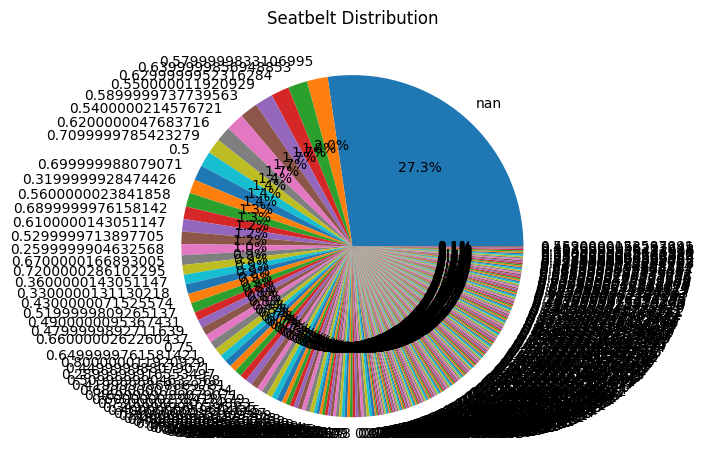

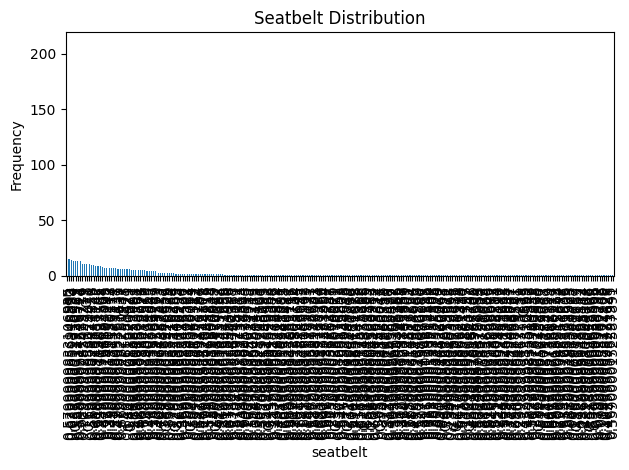


ALCOHOL FREQUENCY
 alcohol
no     676
yes     89
Name: count, dtype: int64
ALCOHOL RELATIVE FREQUENCY
 alcohol
no     0.88366
yes    0.11634
Name: proportion, dtype: float64

STATE FREQUENCY
 state
AK    15
PA    15
ND    15
NE    15
NH    15
NJ    15
NM    15
NV    15
NY    15
OH    15
OK    15
OR    15
RI    15
MT    15
SC    15
SD    15
TN    15
TX    15
UT    15
VA    15
VT    15
WA    15
WI    15
WV    15
NC    15
MS    15
AL    15
IA    15
AR    15
AZ    15
CA    15
CO    15
CT    15
DC    15
DE    15
FL    15
GA    15
HI    15
ID    15
MO    15
IL    15
IN    15
KS    15
KY    15
LA    15
MA    15
MD    15
ME    15
MI    15
MN    15
WY    15
Name: count, dtype: int64
STATE RELATIVE FREQUENCY
 state
AK    0.019608
PA    0.019608
ND    0.019608
NE    0.019608
NH    0.019608
NJ    0.019608
NM    0.019608
NV    0.019608
NY    0.019608
OH    0.019608
OK    0.019608
OR    0.019608
RI    0.019608
MT    0.019608
SC    0.019608
SD    0.019608
TN    0.019608
TX    0.019608
UT    0.019608

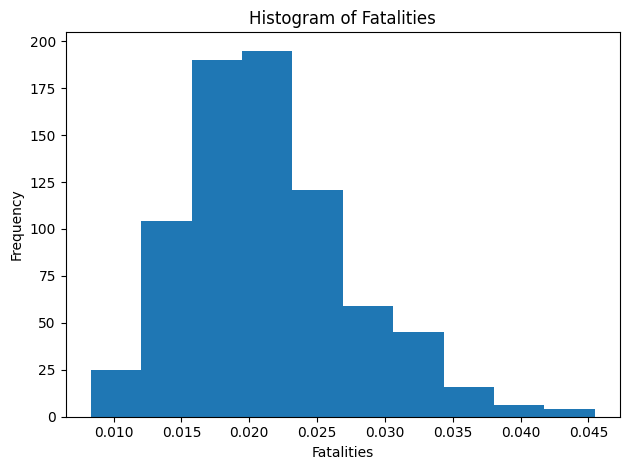

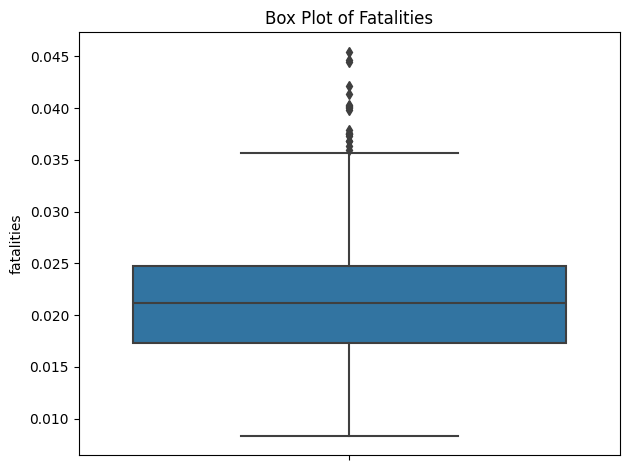

IQR LIMITS: 0.0061914660036562486 0.03592366352677345 
OUTLIER COUNT: 19


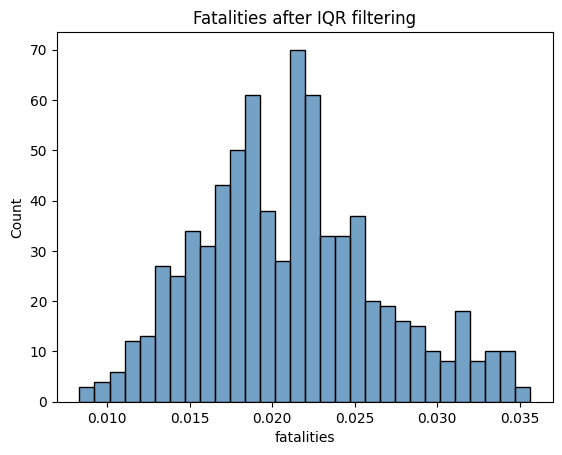

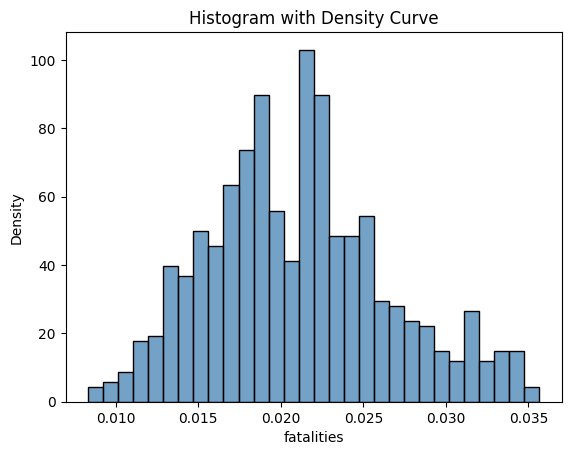

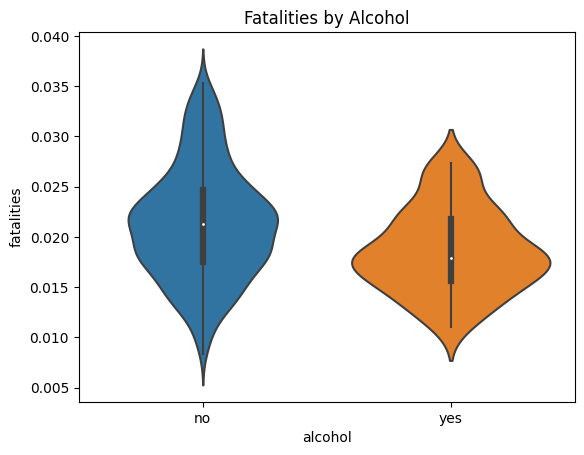

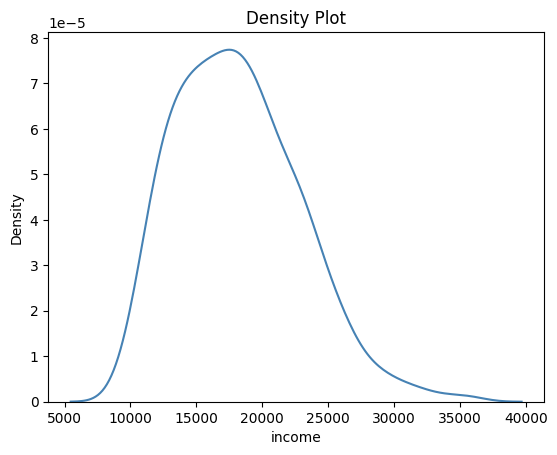


ALCOHOL PROPORTIONS
 alcohol
no     0.88366
yes    0.11634
Name: count, dtype: float64

ALCOHOL PERCENTAGES
 alcohol
no     88.366013
yes    11.633987
Name: count, dtype: float64


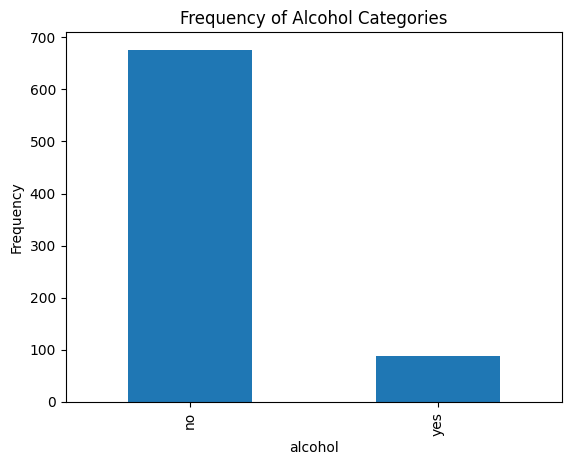

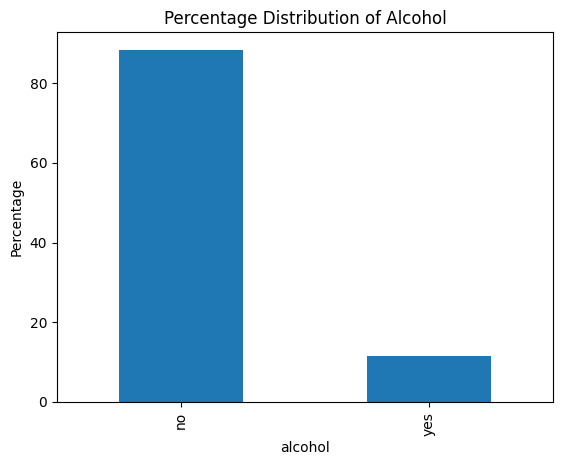

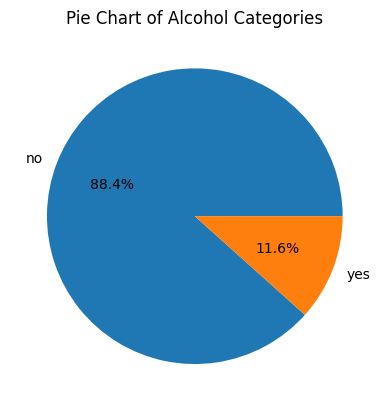

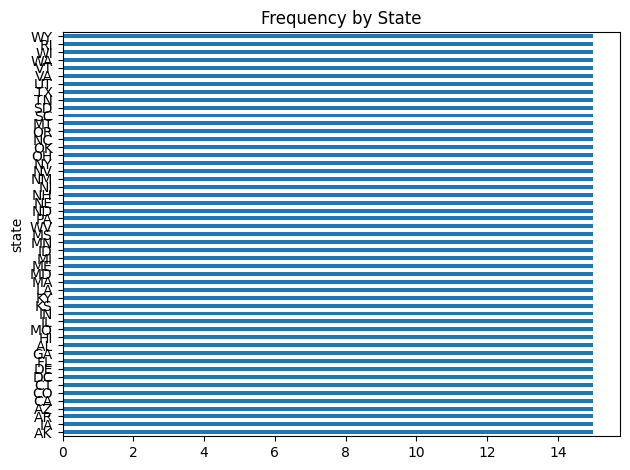


UPPERCASE TEXT SAMPLE
    rownames state  year  miles  fatalities  seatbelt speed65 speed70 drinkage  \
0         1    AK  1983   3358    0.044669       NaN      NO      NO      YES   
1         2    AK  1984   3589    0.037336       NaN      NO      NO      YES   
2         3    AK  1985   3840    0.033073       NaN      NO      NO      YES   
3         4    AK  1986   4008    0.025200       NaN      NO      NO      YES   
4         5    AK  1987   3900    0.019487       NaN      NO      NO      YES   

  alcohol  income        age enforce  
0      NO   17973  28.234966      NO  
1      NO   18093  28.343542      NO  
2      NO   18925  28.372816      NO  
3      NO   18466  28.396652      NO  
4      NO   18021  28.453251      NO  


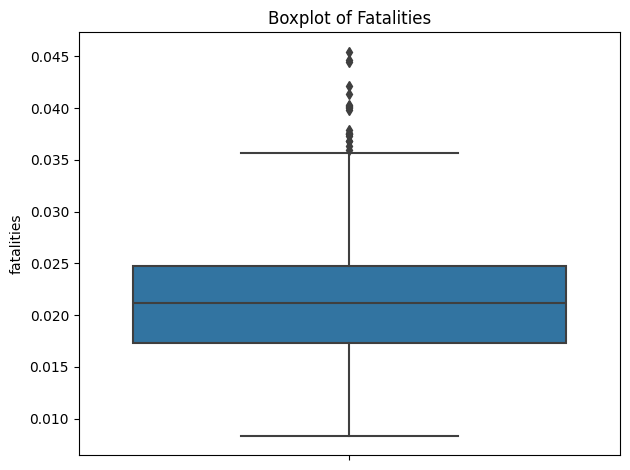

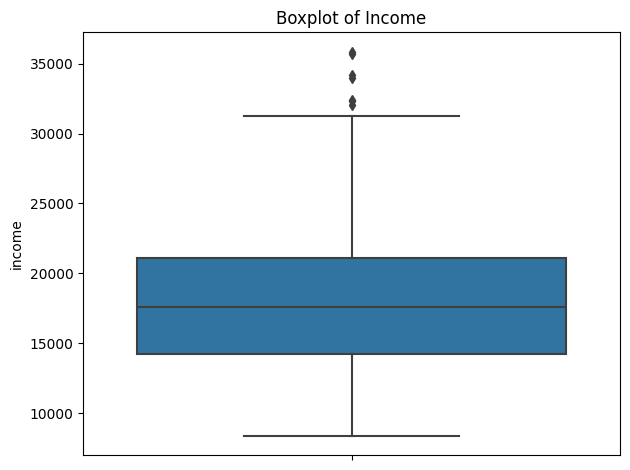

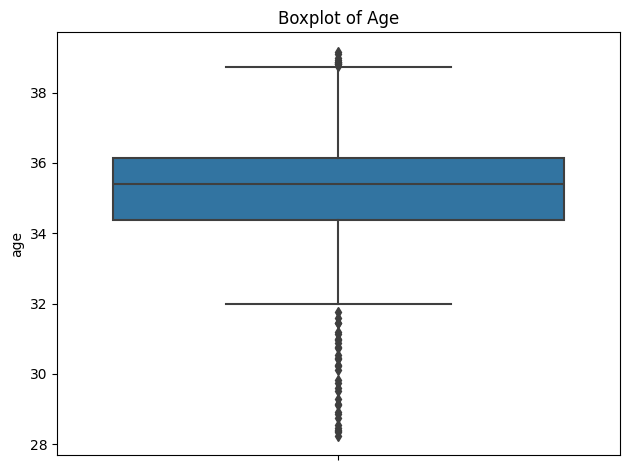

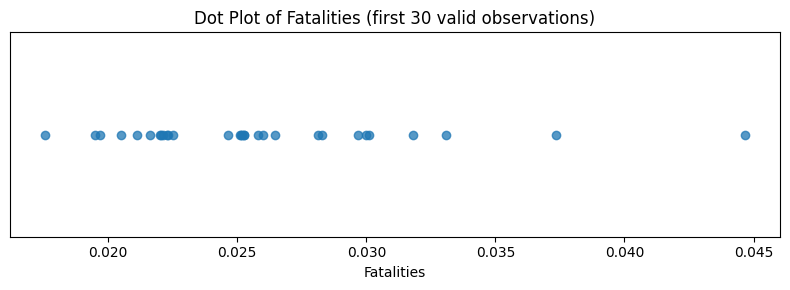

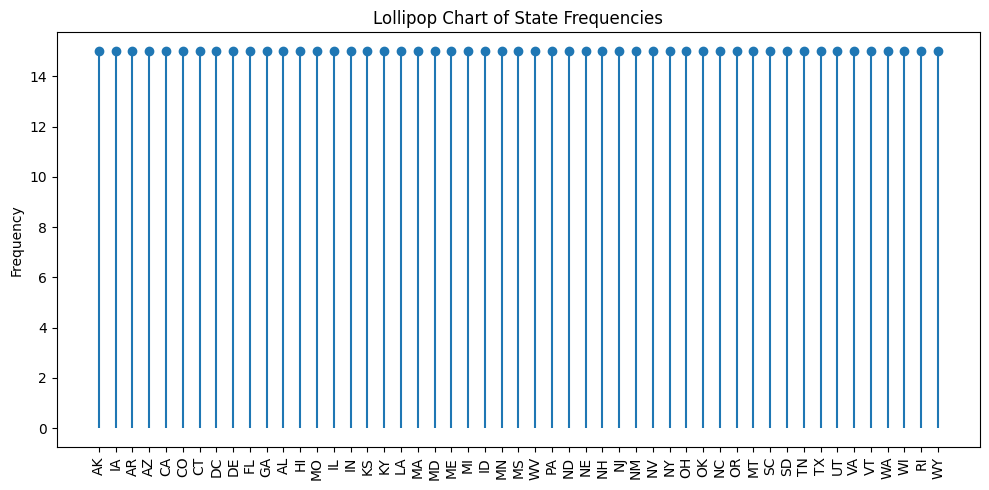

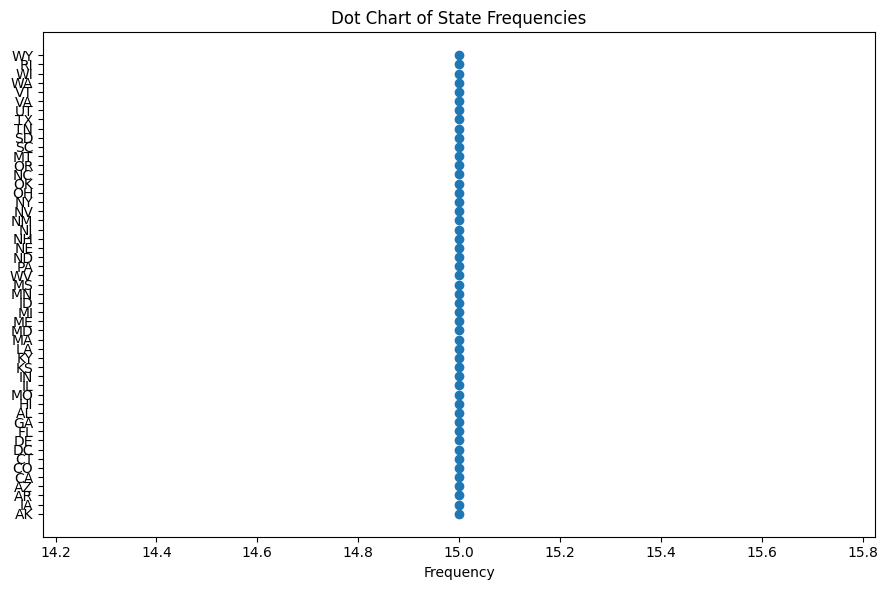

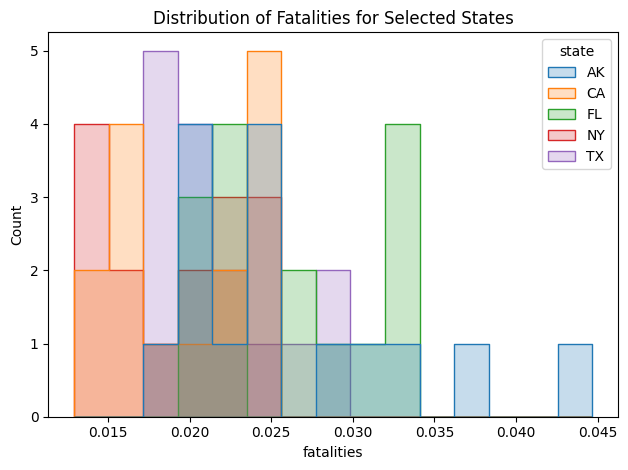

In [5]:
# Assignment 3

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("USSeatBelts.csv")
def show_data(df):
    print("\nSHAPE:", df.shape)
    print("\nCOLUMNS:", list(df.columns))
    print("\nINFO:")
    df.info()
    print("\nFIRST SIX ROWS:\n", df.head(6))
    print("\nLAST SIX ROWS:\n", df.tail(6))
    print("\nSUMMARY:\n", df.describe(include="all").T)

show_data(df)

print("\nMISSING COUNTS\n", df.isna().sum())
print("\nMISSING PERCENTAGE\n", (df.isna().mean()*100).round(2))
print("\nROWS WITH MISSING VALUES\n", df[df.isna().any(axis=1)].head())
# Remove columns with more than 70% missing values.
clean = df.loc[:, df.isna().mean() <= .70].copy()
# Numeric imputations shown as separate strategies.
numeric_cols = clean.select_dtypes(include=np.number).columns
mean_data, median_data = clean.copy(), clean.copy()
for c in numeric_cols:
    if mean_data[c].isna().any() and mean_data[c].notna().any():
        mean_data[c] = mean_data[c].fillna(mean_data[c].mean())
    if median_data[c].isna().any() and median_data[c].notna().any():
        median_data[c] = median_data[c].fillna(median_data[c].median())
mode_data = clean.copy()
for c in mode_data.select_dtypes(exclude=np.number).columns:
    if mode_data[c].isna().any() and not mode_data[c].mode().empty:
        mode_data[c] = mode_data[c].fillna(mode_data[c].mode()[0])
print("\nMEAN IMPUTATION MISSING COUNTS\n", mean_data.isna().sum())
print("\nMEDIAN IMPUTATION MISSING COUNTS\n", median_data.isna().sum())
print("\nMODE IMPUTATION MISSING COUNTS\n", mode_data.isna().sum())
print("\nDUPLICATE ROW COUNT:", mode_data.duplicated().sum())
mode_data = mode_data.drop_duplicates()
print("ROWS AFTER DUPLICATE REMOVAL:", len(mode_data))
# Summary statistics for fatalities.
x = pd.to_numeric(mode_data.get("fatalities"), errors="coerce").dropna()

if len(x):
    print("\nFATALITIES SUMMARY\n", x.describe())
    print("Range:", x.max()-x.min(), "Variance:", x.var(), "SD:", x.std(),
          "IQR:", x.quantile(.75)-x.quantile(.25),
          "Skewness:", x.skew(), "Kurtosis:", x.kurtosis())
# Categorical frequency and relative frequency.
for col in ["seatbelt", "alcohol", "state"]:
    if col in mode_data:
        freq = mode_data[col].value_counts(dropna=False)
        print(f"\n{col.upper()} FREQUENCY\n", freq)
        print(f"{col.upper()} RELATIVE FREQUENCY\n", mode_data[col].value_counts(normalize=True, dropna=False))
        if col == "seatbelt":
            freq.plot(kind="pie", autopct="%1.1f%%", title="Seatbelt Distribution")
            plt.ylabel("")
            plt.tight_layout()
            plt.show()
            freq.plot(kind="bar", title="Seatbelt Distribution")
            plt.xlabel(col)
            plt.ylabel("Frequency")
            plt.tight_layout()
            plt.show()

if len(x):
    print("\nFATALITIES FREQUENCY TABLE\n", pd.cut(x, bins=10).value_counts().sort_index())
    x.plot(kind="hist", bins=10, title="Histogram of Fatalities", xlabel="Fatalities")
    plt.tight_layout()
    plt.show()
    sns.boxplot(y=x)
    plt.title("Box Plot of Fatalities")
    plt.tight_layout()
    plt.show()
    # IQR outlier detection and filtering
    q1, q3 = x.quantile(.25), x.quantile(.75)
    iqr = q3-q1
    low, high = q1-1.5*iqr, q3+1.5*iqr
    outliers = mode_data[(mode_data["fatalities"] < low) | (mode_data["fatalities"] > high)]
    print("IQR LIMITS:", low, high, "\nOUTLIER COUNT:", len(outliers))
    no_outliers = mode_data[mode_data["fatalities"].between(low, high)].copy()
    sns.histplot(no_outliers["fatalities"], bins=30, kde=False, color="steelblue")
    plt.title("Fatalities after IQR filtering")
    plt.show()
    sns.histplot(no_outliers["fatalities"], bins=30, stat="density", kde=False, color="steelblue")
    plt.title("Histogram with Density Curve")
    plt.show()
    if "alcohol" in no_outliers:
        sns.violinplot(data=no_outliers, x="alcohol", y="fatalities")
        plt.title("Fatalities by Alcohol")
        plt.show()
    sns.kdeplot(data=no_outliers, x="income" if "income" in no_outliers else "fatalities", color="steelblue", fill=False)
    plt.title("Density Plot")
    plt.show()
# Proportion/percentage and charts for categorical variables.
if "alcohol" in mode_data:
    counts = mode_data["alcohol"].value_counts()
    print("\nALCOHOL PROPORTIONS\n", counts/counts.sum())
    print("\nALCOHOL PERCENTAGES\n", counts/counts.sum()*100)
    counts.plot(kind="bar", title="Frequency of Alcohol Categories")
    plt.ylabel("Frequency")
    plt.show()
    (counts/counts.sum()*100).plot(kind="bar", title="Percentage Distribution of Alcohol")
    plt.ylabel("Percentage")
    plt.show()
    counts.plot(kind="pie", autopct="%1.1f%%", title="Pie Chart of Alcohol Categories")
    plt.ylabel("")
    plt.show()
if "state" in mode_data:
    mode_data["state"].value_counts().sort_values().plot(kind="barh", title="Frequency by State")
    plt.tight_layout()
    plt.show()

upper_data = mode_data.copy()
for c in upper_data.select_dtypes(include="object").columns:
    upper_data[c] = upper_data[c].str.upper()
print("\nUPPERCASE TEXT SAMPLE\n", upper_data.head())
# Boxplots and IQR outlier analysis for several numerical variables.
for col in ["fatalities", "income", "age"]:
    if col in mode_data:
        sns.boxplot(y=pd.to_numeric(mode_data[col], errors="coerce"))
        plt.title(f"Boxplot of {col.title()}")
        plt.tight_layout()
        plt.show()
# Small-sample dot plot equivalent.
if "fatalities" in mode_data:
    small = pd.to_numeric(mode_data["fatalities"], errors="coerce").dropna().head(30)
    plt.figure(figsize=(8,3))
    plt.scatter(small, np.zeros(len(small)), alpha=.75)
    plt.yticks([])
    plt.xlabel("Fatalities")
    plt.title("Dot Plot of Fatalities (first 30 valid observations)")
    plt.tight_layout()
    plt.show()

# Lollipop and dot charts of state frequencies.
if "state" in mode_data:
    state_freq = mode_data["state"].value_counts().sort_values()
    plt.figure(figsize=(10,5))
    plt.vlines(range(len(state_freq)), 0, state_freq.values)
    plt.scatter(range(len(state_freq)), state_freq.values)
    plt.xticks(range(len(state_freq)), state_freq.index, rotation=90)
    plt.title("Lollipop Chart of State Frequencies")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
    state_freq.plot(kind="scatter", x=None, y=None) if False else None
    plt.figure(figsize=(9,6))
    plt.scatter(state_freq.values, state_freq.index)
    plt.title("Dot Chart of State Frequencies")
    plt.xlabel("Frequency")
    plt.tight_layout()
    plt.show()
# Compare fatality distributions for a few states, if present.
if {"state", "fatalities"}.issubset(mode_data.columns):
    chosen = mode_data[mode_data["state"].astype(str).isin(["AK", "CA", "NY", "TX", "FL"])]
    if not chosen.empty:
        sns.histplot(data=chosen, x="fatalities", hue="state", bins=15, element="step", stat="count", common_norm=False)
        plt.title("Distribution of Fatalities for Selected States")
        plt.tight_layout()
        plt.show()


SHAPE: (765, 13)

COLUMNS: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    object 
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    object 
 7   speed70     765 non-null    object 
 8   drinkage    765 non-null    object 
 9   alcohol     765 non-null    object 
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 77.8+ KB

FIRST SIX ROWS:
    rownames state  year  m

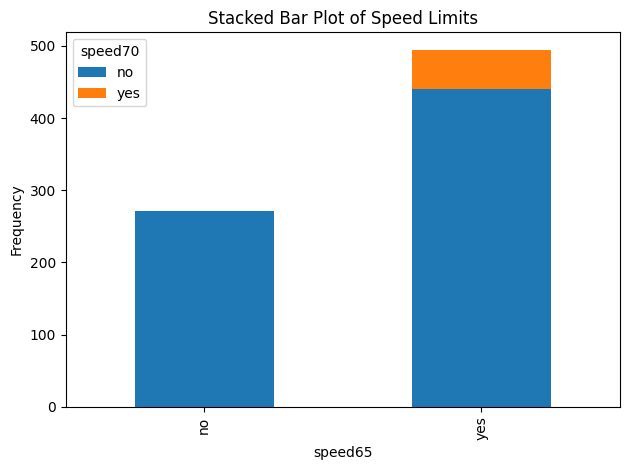

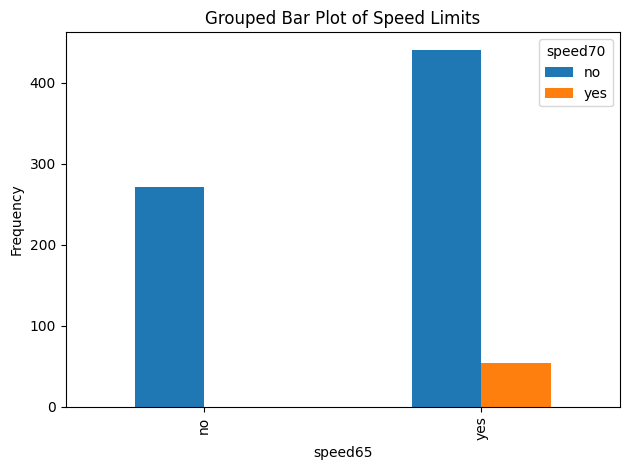

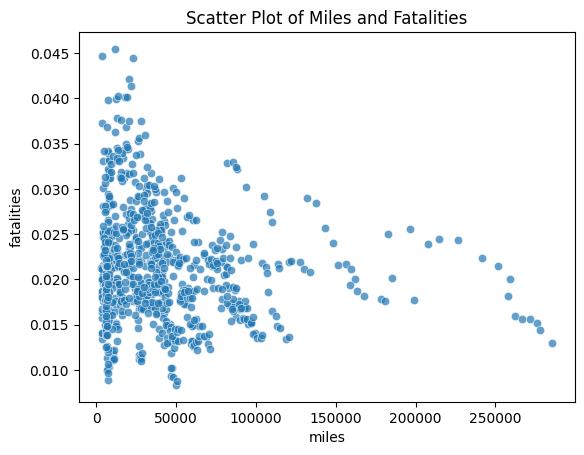

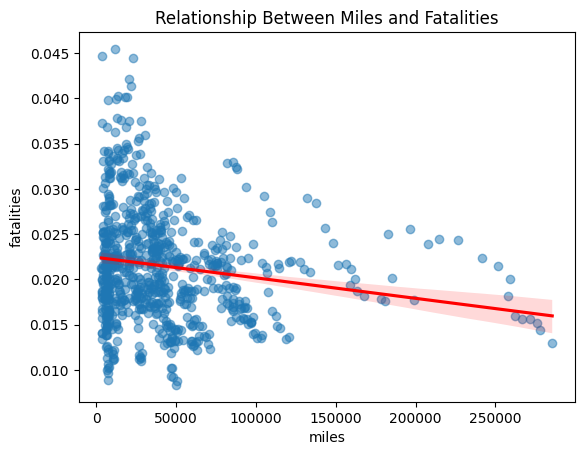

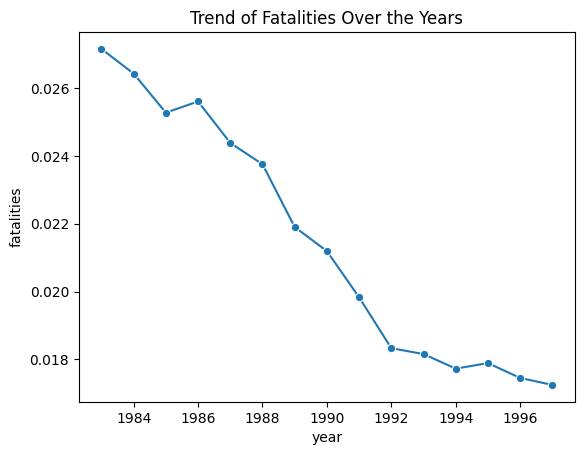


CORRELATION MATRIX
              year  miles  fatalities  income    age
year        1.000  0.123      -0.559   0.781  0.370
miles       0.123  1.000      -0.161   0.206  0.083
fatalities -0.559 -0.161       1.000  -0.704 -0.375
income      0.781  0.206      -0.704   1.000  0.408
age         0.370  0.083      -0.375   0.408  1.000


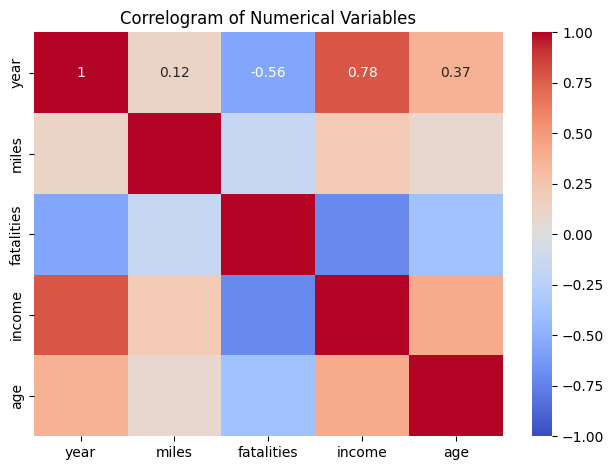


AVERAGE FATALITIES BY SPEED65
   speed65  average_fatalities
0      no            0.023836
1     yes            0.020202


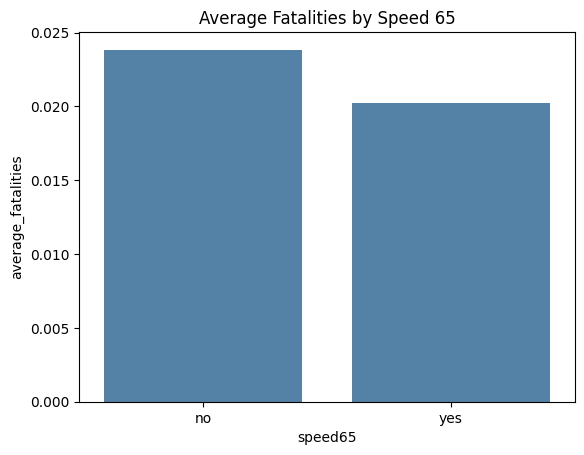

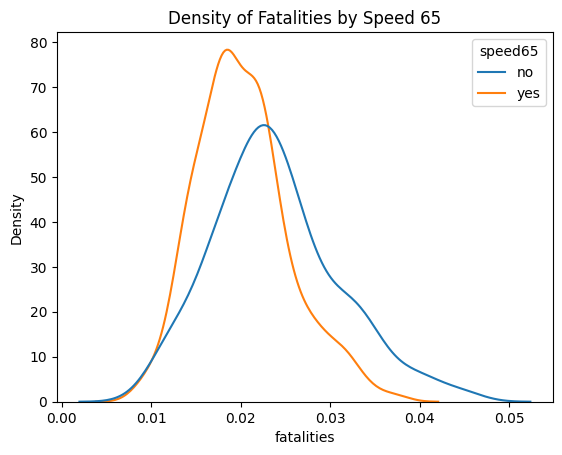

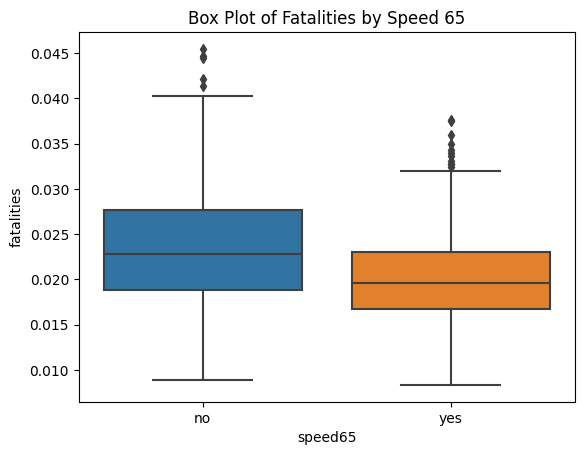

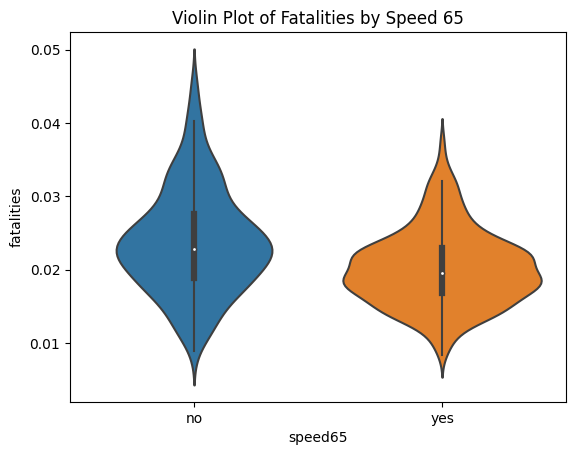

In [6]:
# Assignment 4

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("USSeatBelts.csv")
def show_data(df):
    print("\nSHAPE:", df.shape)
    print("\nCOLUMNS:", list(df.columns))
    print("\nINFO:")
    df.info()
    print("\nFIRST SIX ROWS:\n", df.head(6))
    print("\nLAST SIX ROWS:\n", df.tail(6))
    print("\nSUMMARY:\n", df.describe(include="all").T)

show_data(df)

for c in ["speed65", "speed70", "state", "alcohol"]:
    if c in df: df[c] = df[c].astype("category")
if {"speed65","speed70"}.issubset(df.columns):
    table = pd.crosstab(df["speed65"], df["speed70"])
    print("\nCONTINGENCY TABLE\n", table)
    table.plot(kind="bar", stacked=True, title="Stacked Bar Plot of Speed Limits")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
    table.plot(kind="bar", stacked=False, title="Grouped Bar Plot of Speed Limits")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
if {"miles","fatalities"}.issubset(df.columns):
    sns.scatterplot(data=df, x="miles", y="fatalities", alpha=.7)
    plt.title("Scatter Plot of Miles and Fatalities")
    plt.show()
    sns.regplot(data=df, x="miles", y="fatalities", scatter_kws={"alpha":.5}, line_kws={"color":"red"})
    plt.title("Relationship Between Miles and Fatalities")
    plt.show()
if {"year","fatalities"}.issubset(df.columns):
    annual = df.groupby("year", as_index=False, observed=False)["fatalities"].mean()
    sns.lineplot(data=annual, x="year", y="fatalities", marker="o")
    plt.title("Trend of Fatalities Over the Years")
    plt.show()
num_cols = [c for c in ["year","miles","fatalities","income","age"] if c in df and pd.api.types.is_numeric_dtype(df[c])]
if len(num_cols)>1:
    corr = df[num_cols].corr()
    print("\nCORRELATION MATRIX\n", corr.round(3))
    sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
    plt.title("Correlogram of Numerical Variables")
    plt.tight_layout()
    plt.show()
if {"speed65","fatalities"}.issubset(df.columns):
    bar_data = df.groupby("speed65", observed=False)["fatalities"].mean().reset_index(name="average_fatalities")
    print("\nAVERAGE FATALITIES BY SPEED65\n", bar_data)
    sns.barplot(data=bar_data, x="speed65", y="average_fatalities", color="steelblue")
    plt.title("Average Fatalities by Speed 65")
    plt.show()
    sns.kdeplot(data=df, x="fatalities", hue="speed65", fill=False, common_norm=False)
    plt.title("Density of Fatalities by Speed 65")
    plt.show()
    sns.boxplot(data=df, x="speed65", y="fatalities")
    plt.title("Box Plot of Fatalities by Speed 65")
    plt.show()
    sns.violinplot(data=df, x="speed65", y="fatalities")
    plt.title("Violin Plot of Fatalities by Speed 65")
    plt.show()


SHAPE: (765, 13)

COLUMNS: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    object 
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    object 
 7   speed70     765 non-null    object 
 8   drinkage    765 non-null    object 
 9   alcohol     765 non-null    object 
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 77.8+ KB

FIRST SIX ROWS:
    rownames state  year  m

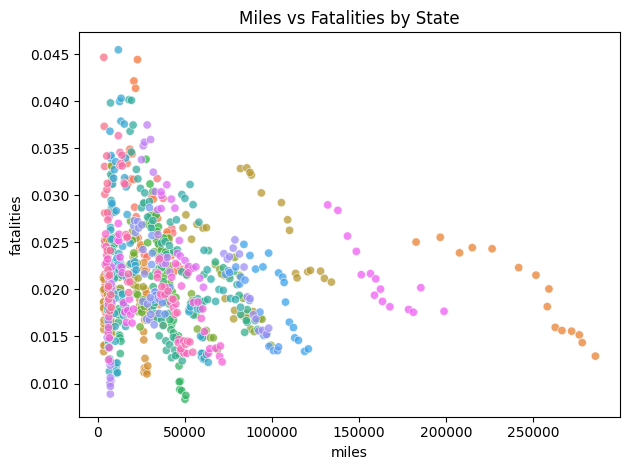

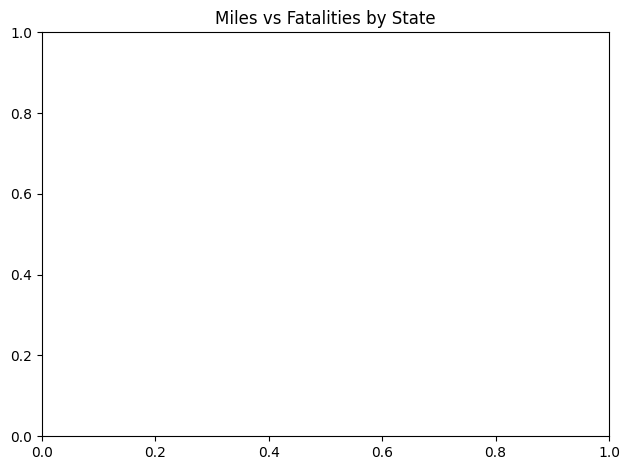

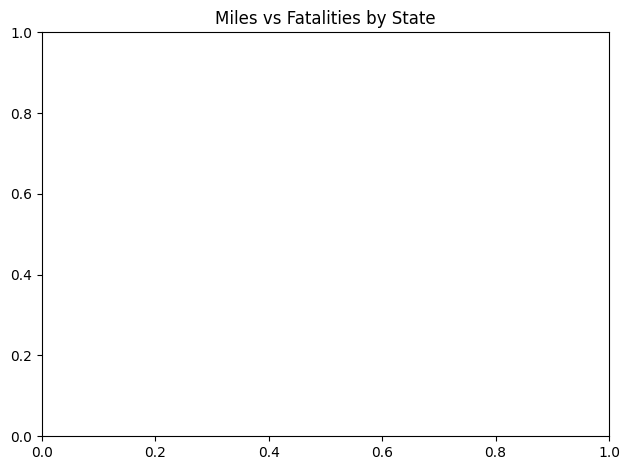

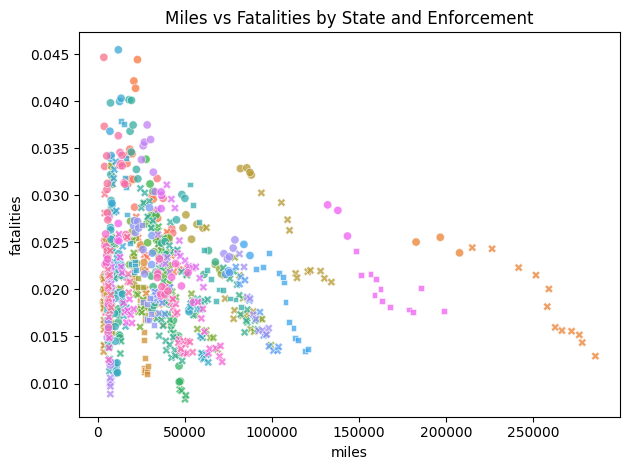

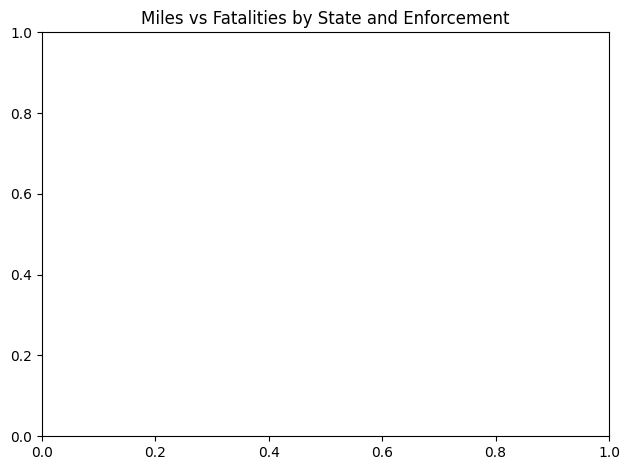

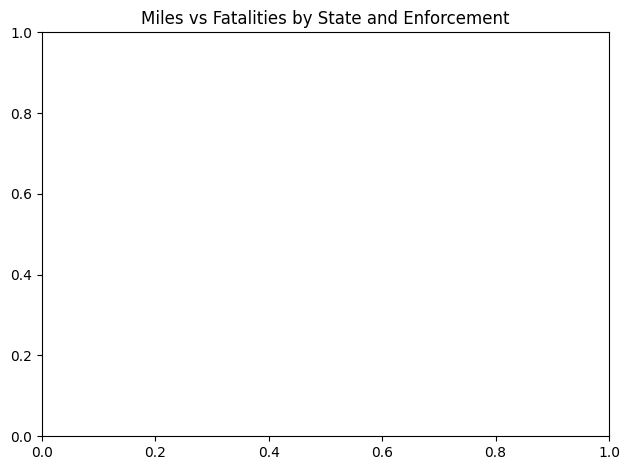

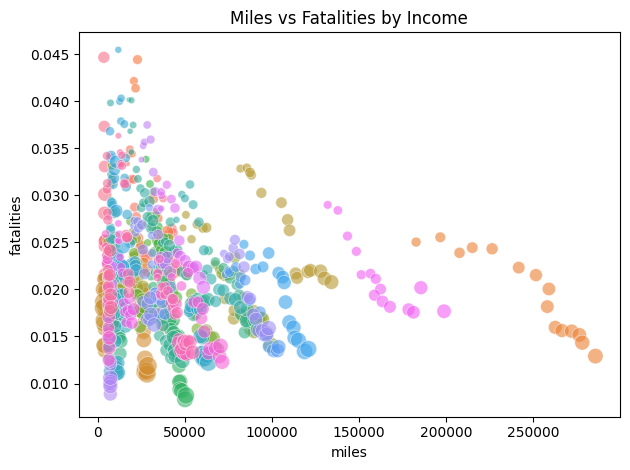

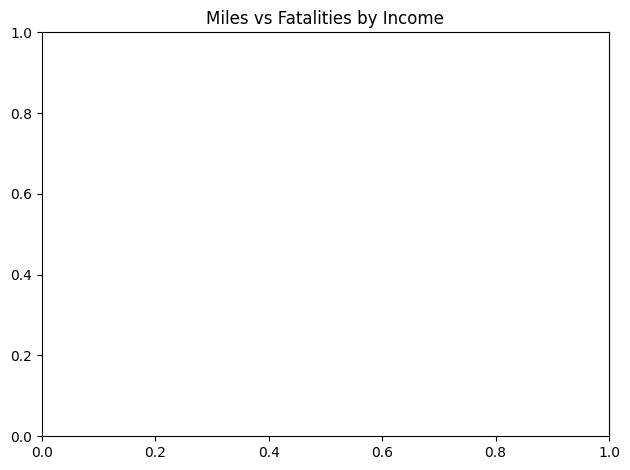

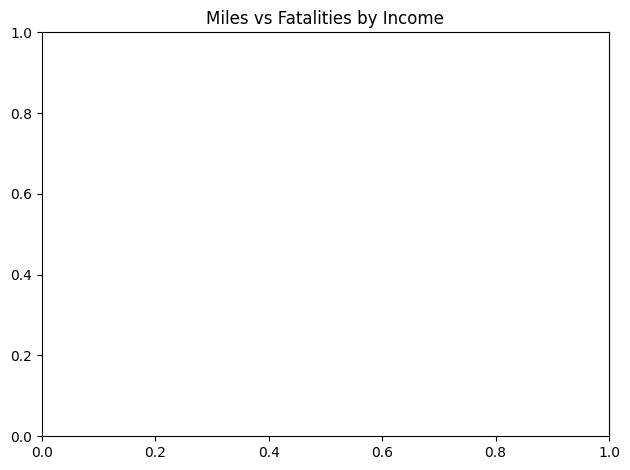

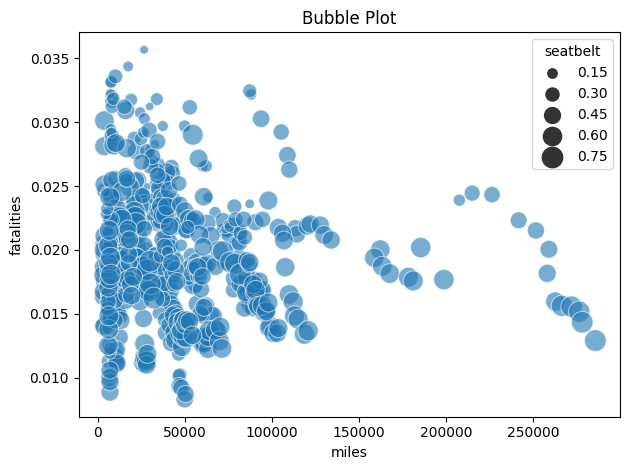

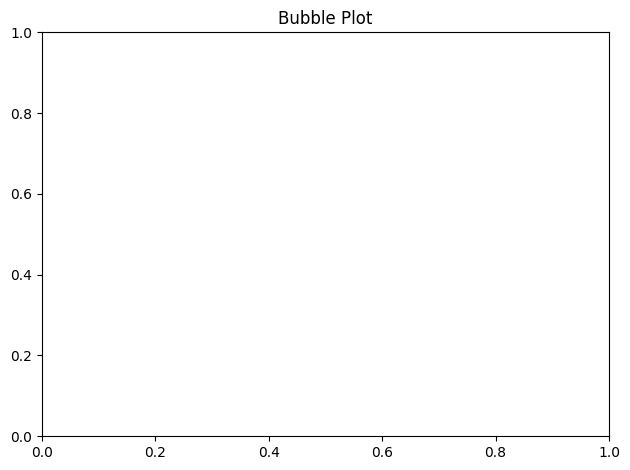

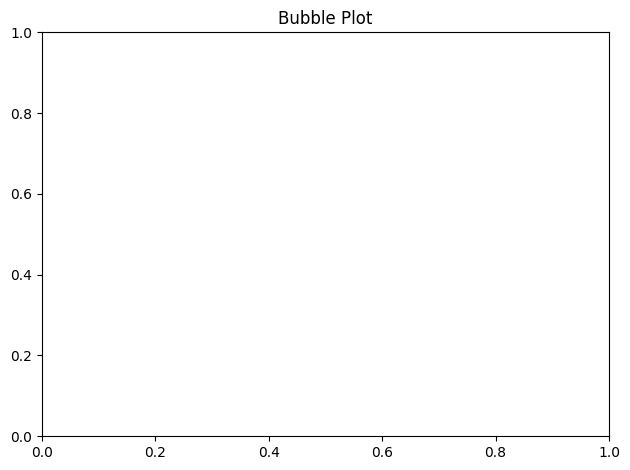

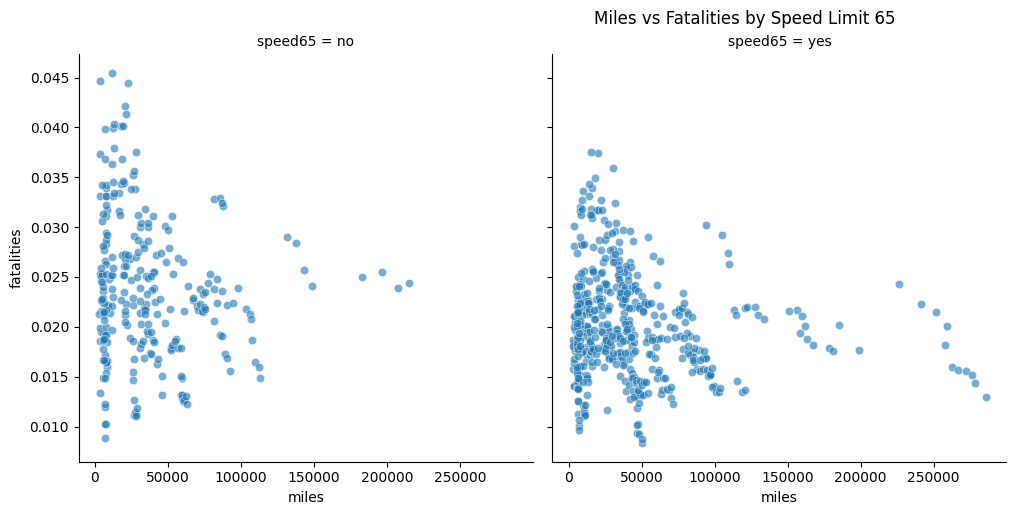

<Figure size 640x480 with 0 Axes>

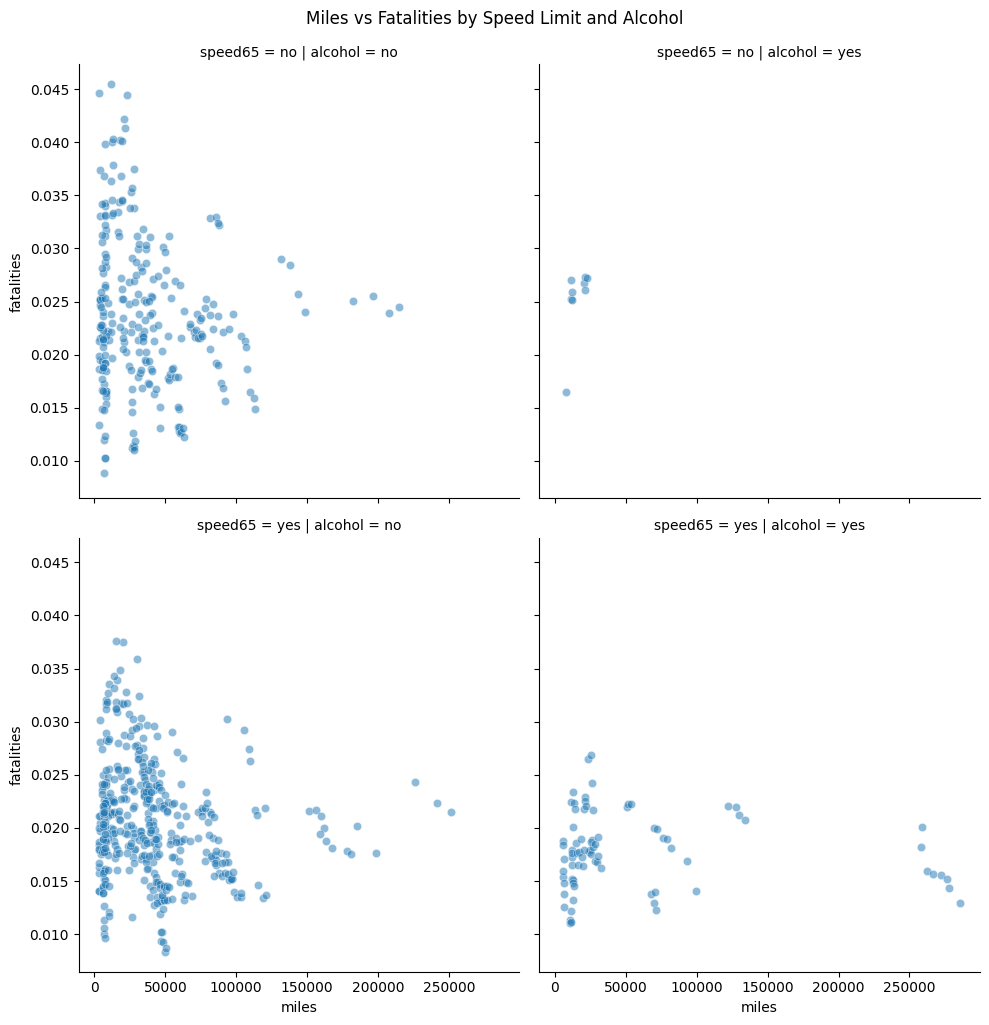

<Figure size 640x480 with 0 Axes>

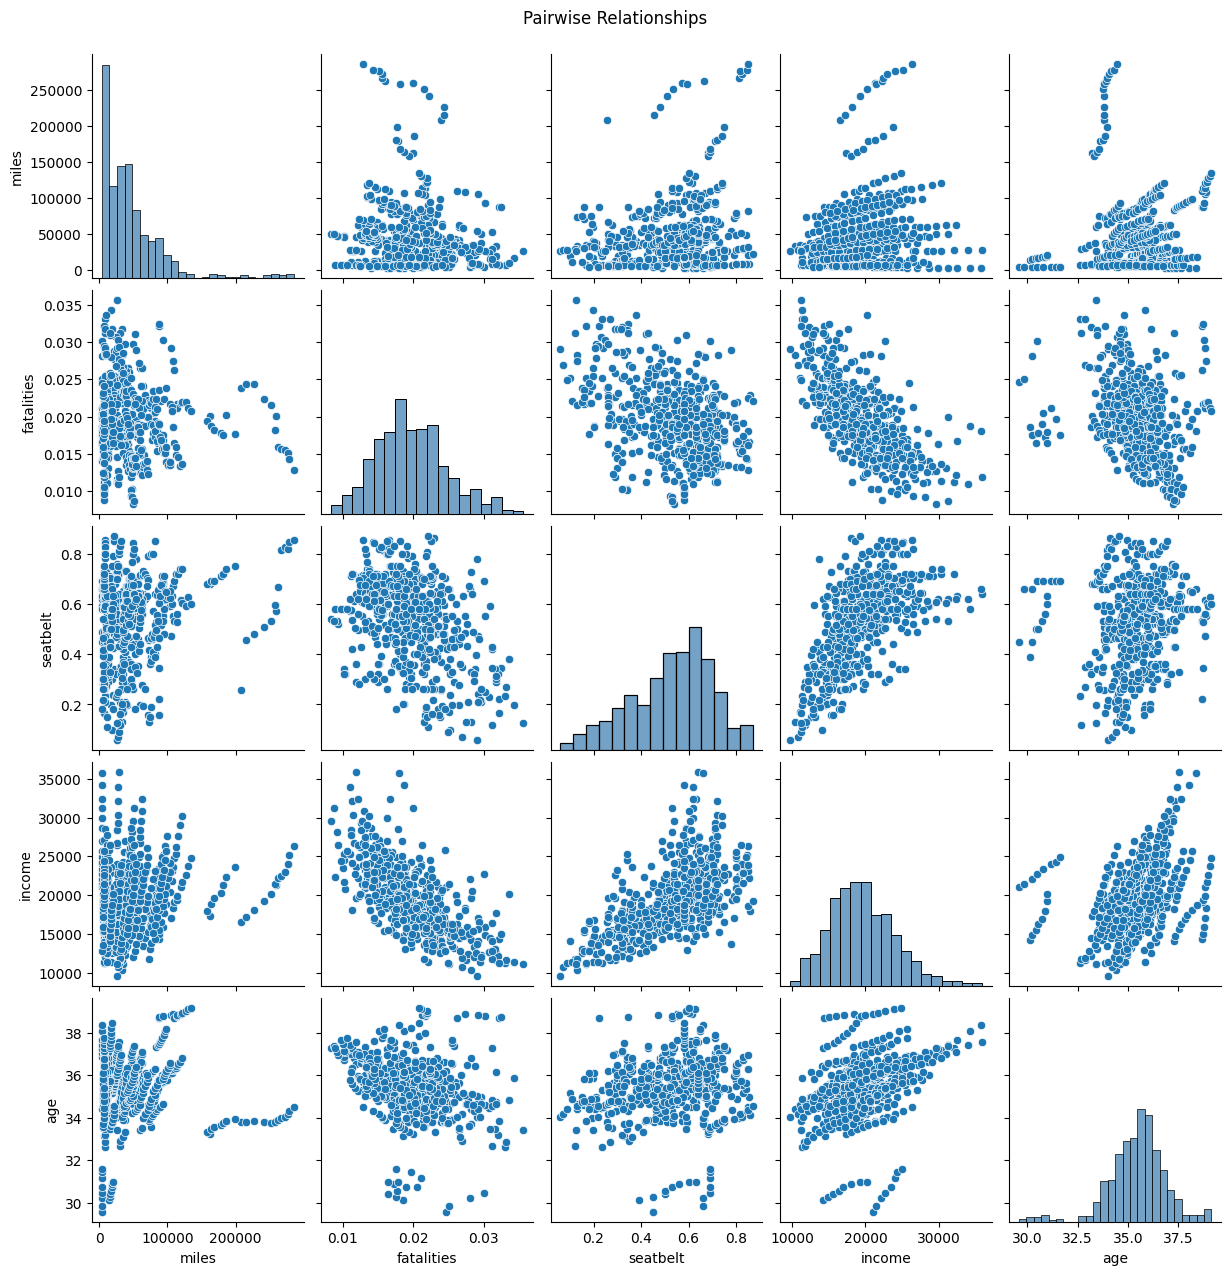

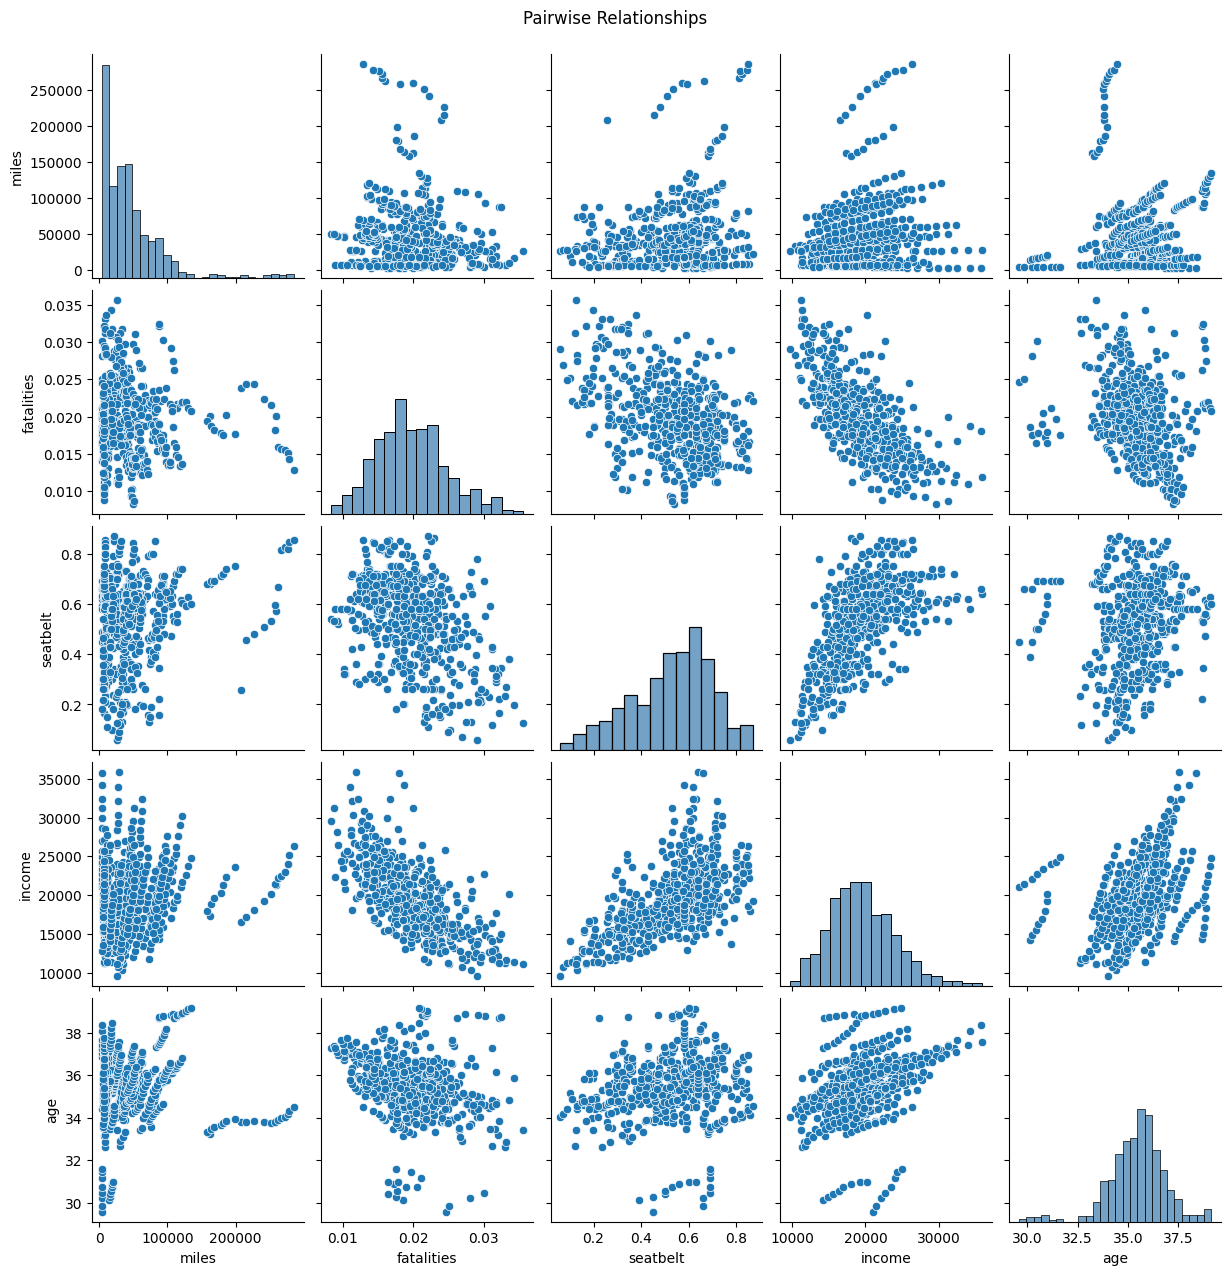

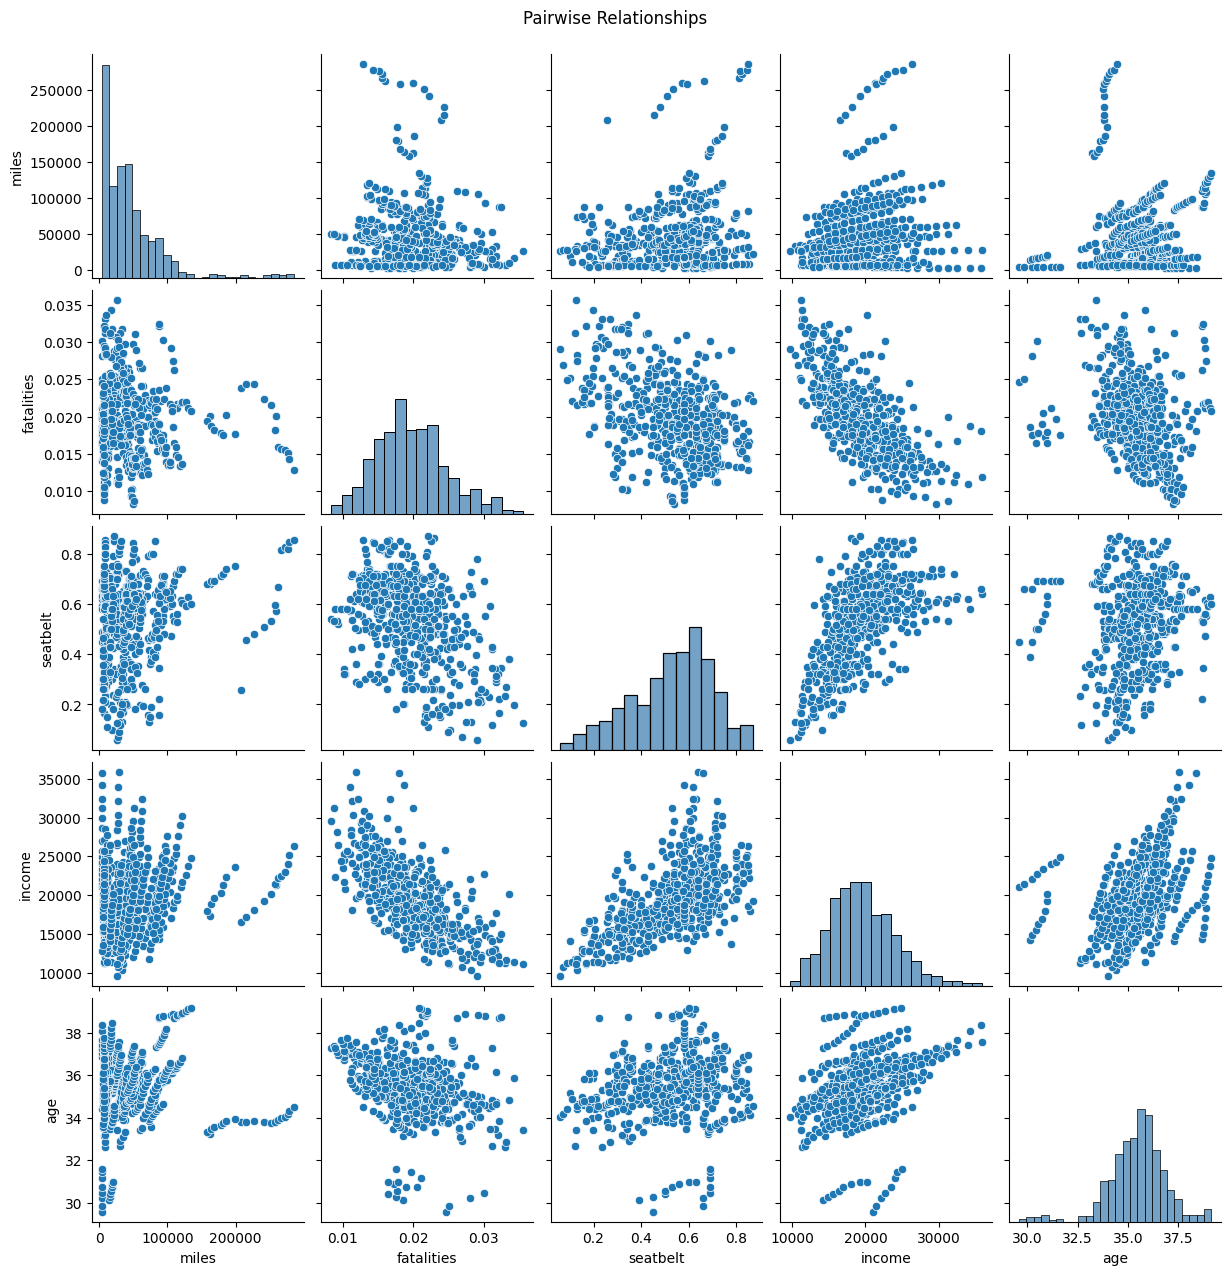

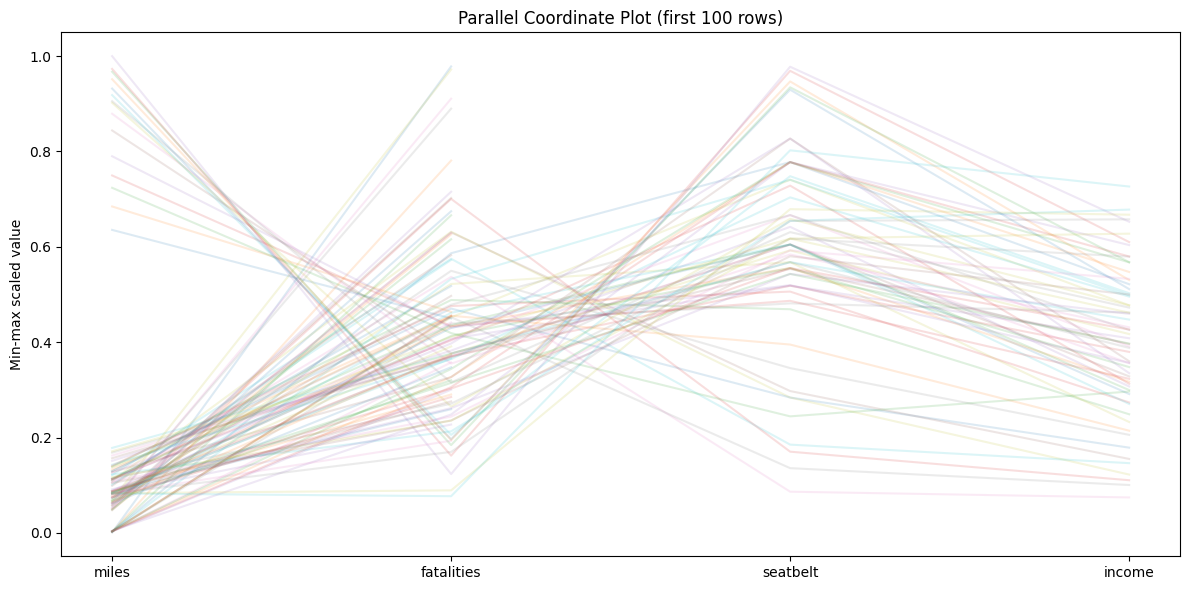

In [7]:
# Assignment 5

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("USSeatBelts.csv")
def show_data(df):
    print("\nSHAPE:", df.shape)
    print("\nCOLUMNS:", list(df.columns))
    print("\nINFO:")
    df.info()
    print("\nFIRST SIX ROWS:\n", df.head(6))
    print("\nLAST SIX ROWS:\n", df.tail(6))
    print("\nSUMMARY:\n", df.describe(include="all").T)

show_data(df)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print("\nNUMERICAL VARIABLES:", numeric_cols)
print("CATEGORICAL VARIABLES:", categorical_cols)
sns.scatterplot(data=df, x="miles", y="fatalities", hue="state", legend=False, alpha=.75)
plt.title("Miles vs Fatalities by State")
plt.tight_layout()
plt.show()
plt.title("Miles vs Fatalities by State")
plt.tight_layout()
plt.show()
plt.title("Miles vs Fatalities by State")
plt.tight_layout()
plt.show()
sns.scatterplot(data=df, x="miles", y="fatalities", hue="state", style="enforce", alpha=.75, legend=False)
plt.title("Miles vs Fatalities by State and Enforcement")
plt.tight_layout()
plt.show()
plt.title("Miles vs Fatalities by State and Enforcement")
plt.tight_layout()
plt.show()
plt.title("Miles vs Fatalities by State and Enforcement")
plt.tight_layout()
plt.show()
sns.scatterplot(data=df, x="miles", y="fatalities", hue="state", size="income", sizes=(15,180), alpha=.6, legend=False)
plt.title("Miles vs Fatalities by Income")
plt.tight_layout()
plt.show()
plt.title("Miles vs Fatalities by Income")
plt.tight_layout()
plt.show()
plt.title("Miles vs Fatalities by Income")
plt.tight_layout()
plt.show()
sns.scatterplot(data=df, x="miles", y="fatalities", size="seatbelt", sizes=(20,250), alpha=.6)
plt.title("Bubble Plot")
plt.tight_layout()
plt.show()
plt.title("Bubble Plot")
plt.tight_layout()
plt.show()
plt.title("Bubble Plot")
plt.tight_layout()
plt.show()
sns.relplot(data=df, x="miles", y="fatalities", col="speed65", col_wrap=3, kind="scatter", alpha=.6)
plt.suptitle("Miles vs Fatalities by Speed Limit 65", y=1.02)
plt.show()
plt.suptitle("Miles vs Fatalities by Speed Limit 65", y=1.02)
plt.show()
sns.relplot(data=df, x="miles", y="fatalities", col="alcohol", row="speed65", kind="scatter", alpha=.5)
plt.suptitle("Miles vs Fatalities by Speed Limit and Alcohol", y=1.02)
plt.show()
plt.suptitle("Miles vs Fatalities by Speed Limit and Alcohol", y=1.02)
plt.show()
pairs = [c for c in ["miles","fatalities","seatbelt","income","age"] if c in df]
sns.pairplot(df[pairs].dropna(), diag_kws={"color": "steelblue"})
plt.suptitle("Pairwise Relationships", y=1.02)
plt.show()

sns.pairplot(df[pairs].dropna(), diag_kws={"color": "steelblue"})
plt.suptitle("Pairwise Relationships", y=1.02)
plt.show()
sns.pairplot(df[pairs].dropna(), diag_kws={"color": "steelblue"})
plt.suptitle("Pairwise Relationships", y=1.02)
plt.show()
parallel_cols = [c for c in ["miles","fatalities","seatbelt","income"] if c in df]
if len(parallel_cols)>1:
    scaled = df[parallel_cols].apply(lambda s: (s-s.min())/(s.max()-s.min()) if s.max()!=s.min() else 0)
    plt.figure(figsize=(12,6))
    for _, row in scaled.head(100).iterrows():
        plt.plot(range(len(parallel_cols)), row.values, alpha=.15)
    plt.xticks(range(len(parallel_cols)), parallel_cols)
    plt.title("Parallel Coordinate Plot (first 100 rows)")
    plt.ylabel("Min-max scaled value")
    plt.tight_layout()
    plt.show()

AIRPASSENGERS TIME SERIES ANALYSIS

1. FIRST FIVE OBSERVATIONS
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS

2. LAST FIVE OBSERVATIONS
1960-08-01    606.0
1960-09-01    508.0
1960-10-01    461.0
1960-11-01    390.0
1960-12-01    432.0
Freq: MS

3-4. TIME SERIES CHARACTERISTICS
Start period: 1949-01
End period: 1960-12
Frequency: 12 observations per year (monthly)
Class: pandas.Series
Number of observations: 144
Time interval: MS

SUMMARY STATISTICS
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000

5. MONTHLY PASSENGER TREND


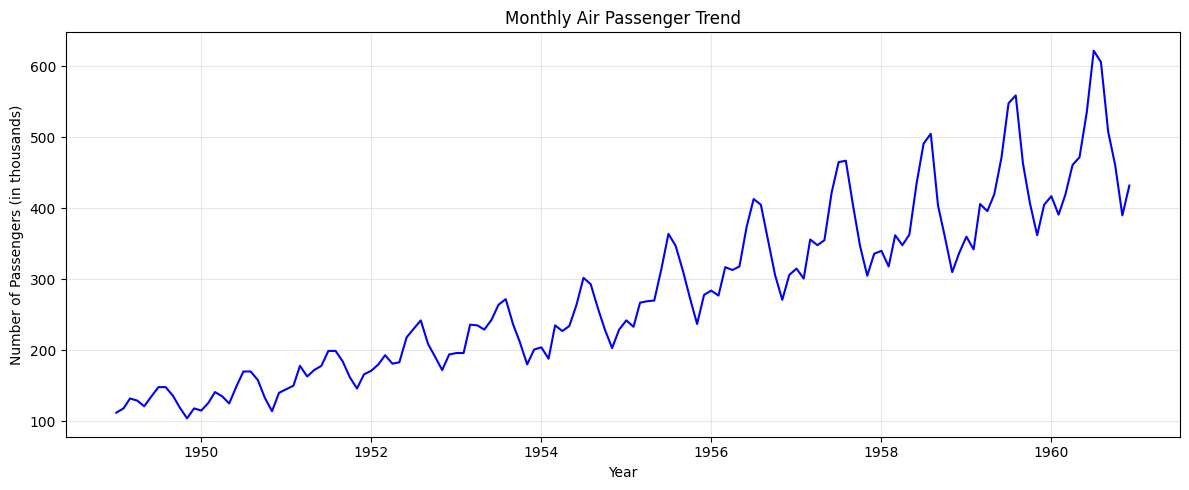


6-7. SEASONAL DECOMPOSITION


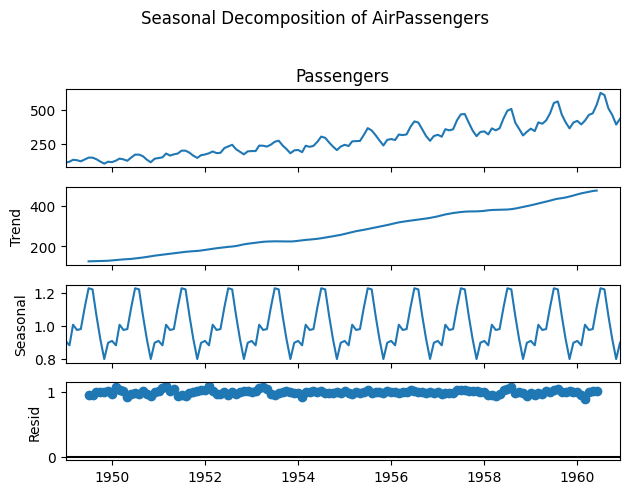


8. AUTOCORRELATION FUNCTION (ACF)


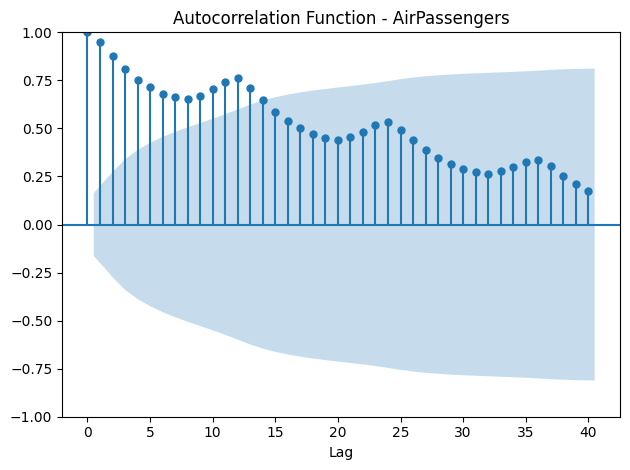


8. PARTIAL AUTOCORRELATION FUNCTION (PACF)


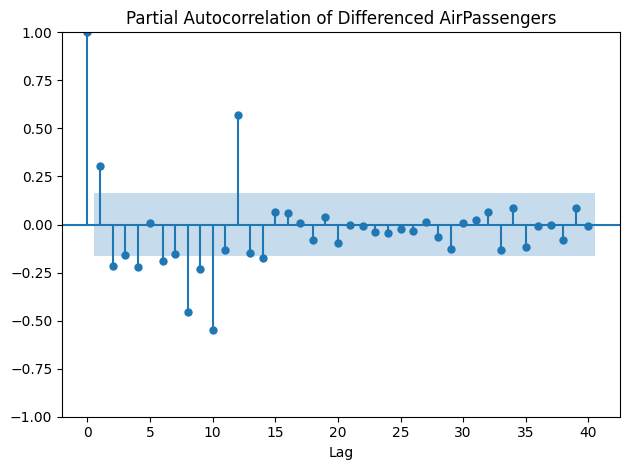


9-10. FITTING ARIMA(1,1,1) MODEL

ARIMA(1,1,1) MODEL SUMMARY
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -694.341
Date:                Sun, 01 Nov 2026   AIC                           1394.683
Time:                        13:57:04   BIC                           1403.571
Sample:                    01-01-1949   HQIC                          1398.294
                         - 12-01-1960                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4742      0.123     -3.847      0.000      -0.716      -0.233
ma.L1          0.8635      0.078     11.051      0.000       0.710   

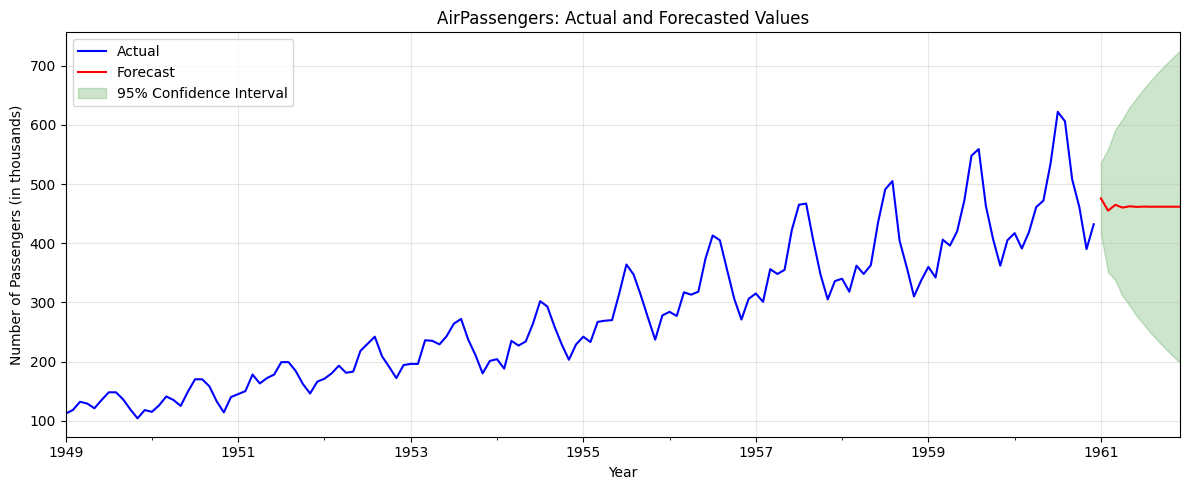

In [8]:
# Assignment 6

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.datasets import get_rdataset
passenger_values = np.array([
    112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118,
    115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140,
    145, 150, 178, 163, 172, 178, 199, 199, 184, 162, 146, 166,
    171, 180, 193, 181, 183, 218, 230, 242, 209, 191, 172, 194,
    196, 196, 236, 235, 229, 243, 264, 272, 237, 211, 180, 201,
    204, 188, 235, 227, 234, 264, 302, 293, 259, 229, 203, 229,
    242, 233, 267, 269, 270, 315, 364, 347, 312, 274, 237, 278,
    284, 277, 317, 313, 318, 374, 413, 405, 355, 306, 271, 306,
    315, 301, 356, 348, 355, 422, 465, 467, 404, 347, 305, 336,
    340, 318, 362, 348, 363, 435, 491, 505, 404, 359, 310, 337,
    360, 342, 406, 396, 420, 472, 548, 559, 463, 407, 362, 405,
    417, 391, 419, 461, 472, 535, 622, 606, 508, 461, 390, 432
], dtype=float)

try:
    air = get_rdataset("AirPassengers", "datasets").data

    if "value" in air.columns:
        online_values = air["value"].astype(float).to_numpy()
    elif "Passengers" in air.columns:
        online_values = air["Passengers"].astype(float).to_numpy()
    else:
        online_values = np.array([])

    if (
        len(online_values) == 144
        and np.all(np.isfinite(online_values))
        and online_values.min() >= 50
        and online_values.max() <= 1000
    ):
        values = online_values
    else:
        values = passenger_values

except Exception:
    values = passenger_values
if len(values) != 144:
    raise ValueError("AirPassengers dataset must contain 144 observations.")
dates = pd.date_range(start="1949-01-01", periods=144, freq="MS")
ts = pd.Series(values, index=dates, name="Passengers")
print("=" * 60)
print("AIRPASSENGERS TIME SERIES ANALYSIS")

print("=" * 60)
print("\n1. FIRST FIVE OBSERVATIONS")
print(ts.head().to_string())
print("\n2. LAST FIVE OBSERVATIONS")
print(ts.tail().to_string())
print("\n3-4. TIME SERIES CHARACTERISTICS")
print("Start period:", ts.index.min().strftime("%Y-%m"))
print("End period:", ts.index.max().strftime("%Y-%m"))
print("Frequency: 12 observations per year (monthly)")
print("Class: pandas.Series")
print("Number of observations:", len(ts))
print("Time interval:", ts.index.freqstr)
print("\nSUMMARY STATISTICS")
print(ts.describe().to_string())
print("\n5. MONTHLY PASSENGER TREND")
plt.figure(figsize=(12, 5))
plt.plot(ts.index, ts.values, color="blue")
plt.title("Monthly Air Passenger Trend")
plt.xlabel("Year")
plt.ylabel("Number of Passengers (in thousands)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("\n6-7. SEASONAL DECOMPOSITION")
decomp = seasonal_decompose(ts, model="multiplicative", period=12)
decomp.plot()
plt.suptitle("Seasonal Decomposition of AirPassengers", y=1.02)
plt.tight_layout()

plt.show()
print("\n8. AUTOCORRELATION FUNCTION (ACF)")
plot_acf(ts, lags=40)
plt.title("Autocorrelation Function - AirPassengers")
plt.xlabel("Lag")
plt.tight_layout()
plt.show()
print("\n8. PARTIAL AUTOCORRELATION FUNCTION (PACF)")
plot_pacf(ts.diff().dropna(), lags=40, method="ywm")
plt.title("Partial Autocorrelation of Differenced AirPassengers")
plt.xlabel("Lag")
plt.tight_layout()
plt.show()
print("\n9-10. FITTING ARIMA(1,1,1) MODEL")
model = ARIMA(ts, order=(1, 1, 1)).fit()
print("\nARIMA(1,1,1) MODEL SUMMARY")
print(model.summary())
print("\n11. FORECAST FOR THE NEXT 12 MONTHS")
pred = model.get_forecast(steps=12)
forecast = pred.predicted_mean
ci = pred.conf_int()
forecast_table = pd.DataFrame({
    "Forecast": forecast,
    "Lower 95% CI": ci.iloc[:, 0],
    "Upper 95% CI": ci.iloc[:, 1]
})
print(forecast_table.round(2).to_string())
print("\n12. ACTUAL VS FORECASTED PASSENGER VALUES")

fig, ax = plt.subplots(figsize=(12, 5))
ts.plot(ax=ax, label="Actual", color="blue")
forecast.plot(ax=ax, label="Forecast", color="red")
ax.fill_between(
    ci.index,
    ci.iloc[:, 0].to_numpy(),
    ci.iloc[:, 1].to_numpy(),
    color="green",
    alpha=0.2,
    label="95% Confidence Interval"
)
ax.set_title("AirPassengers: Actual and Forecasted Values")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Passengers (in thousands)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


DATASET INFORMATION

Shape: (765, 13)

Columns: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    object 
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    object 
 7   speed70     765 non-null    object 
 8   drinkage    765 non-null    object 
 9   alcohol     765 non-null    object 
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 77.8+ KB

First six rows:


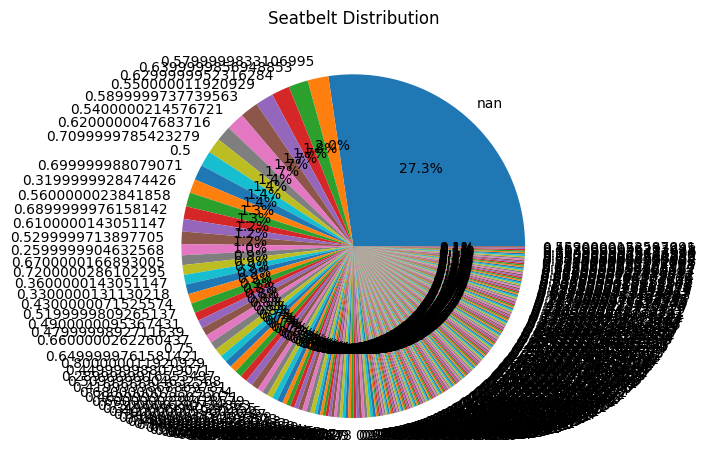

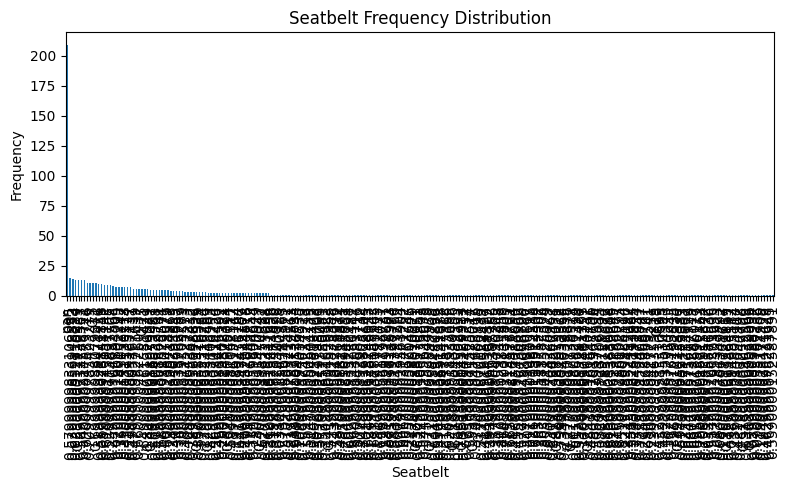


FATALITIES FREQUENCY DISTRIBUTION BY INTERVAL
fatalities
(0.00829, 0.012]     25
(0.012, 0.0158]     104
(0.0158, 0.0195]    190
(0.0195, 0.0232]    195
(0.0232, 0.0269]    121
(0.0269, 0.0306]     59
(0.0306, 0.0343]     45
(0.0343, 0.038]      16
(0.038, 0.0418]       6
(0.0418, 0.0455]      4


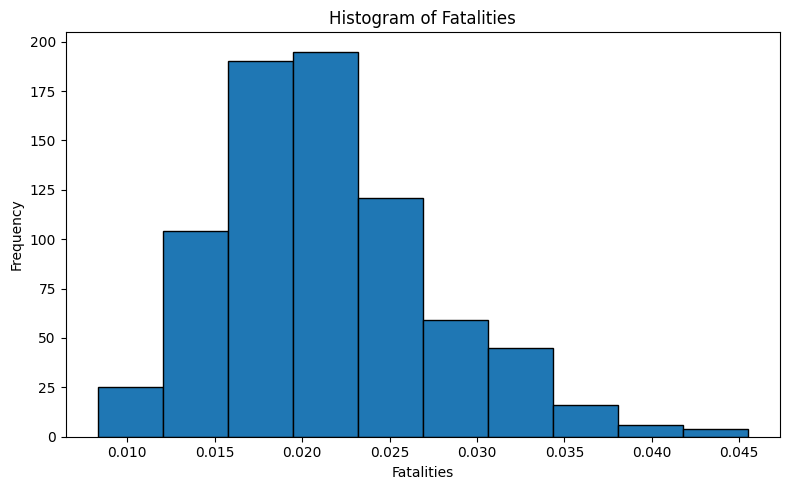

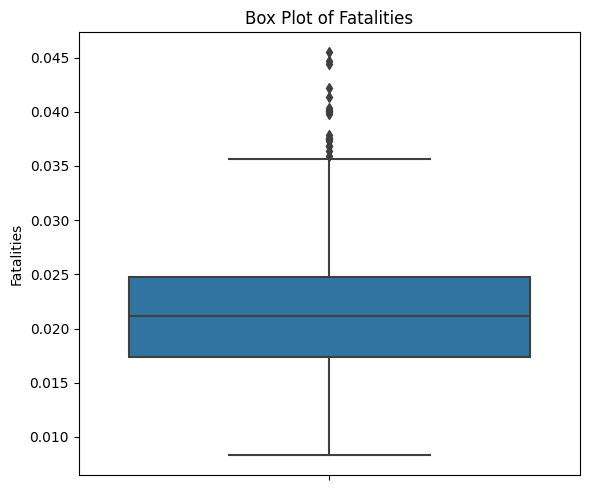


CONTINGENCY TABLE: SPEED65 VS SPEED70
speed70   no  yes
speed65          
no       271    0
yes      440   54

ROW PROPORTIONS
speed70      no     yes
speed65                
no       1.0000  0.0000
yes      0.8907  0.1093

COLUMN PROPORTIONS
speed70      no  yes
speed65             
no       0.3812  0.0
yes      0.6188  1.0


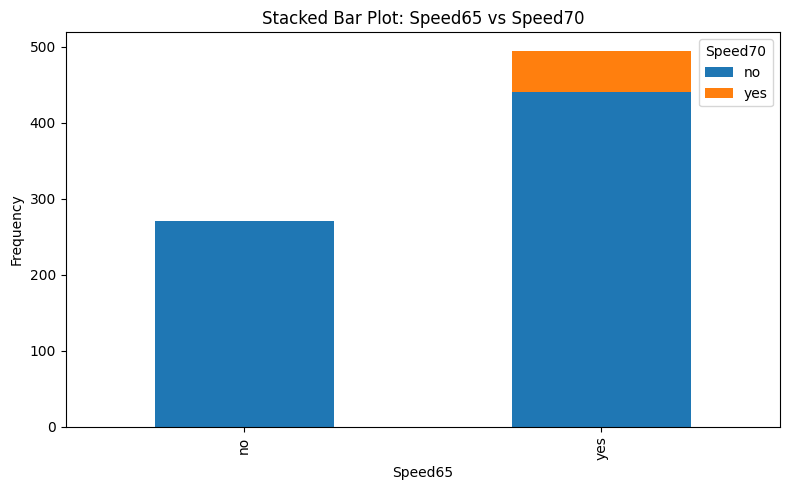


FATALITIES STATISTICS GROUPED BY SPEED65
             mean    median       std
speed65                              
no       0.023836  0.022840  0.007072
yes      0.020202  0.019554  0.005191


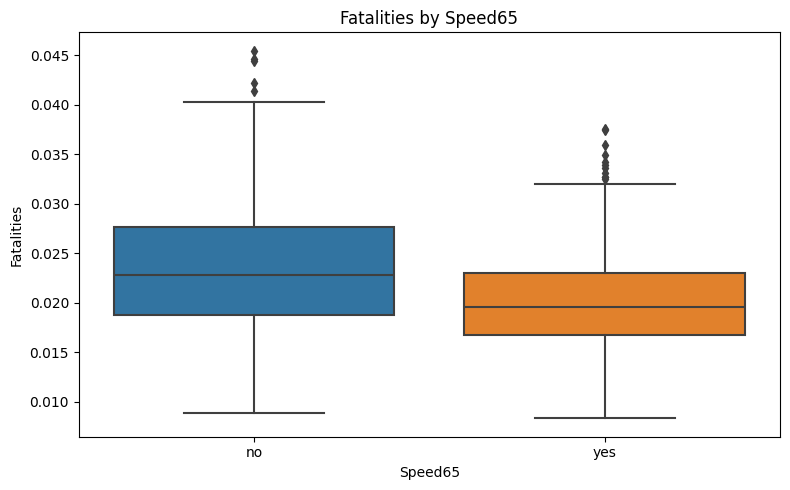

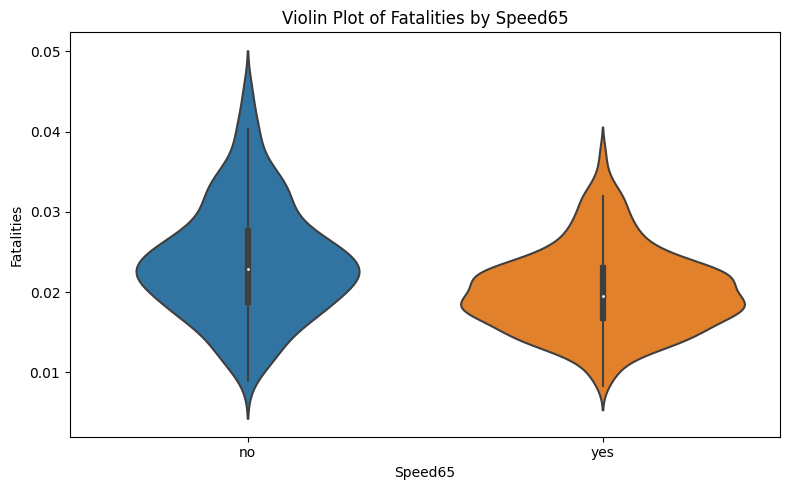


PEARSON CORRELATION
PearsonRResult(statistic=-0.16136607147560542, pvalue=7.281379796112726e-06)

SPEARMAN CORRELATION
SignificanceResult(statistic=-0.1512044260875675, pvalue=2.6758003710262204e-05)


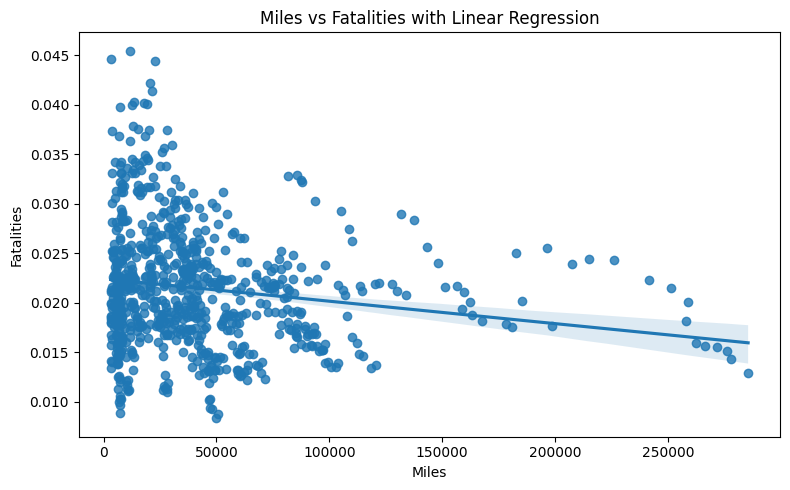


MEAN AND STANDARD DEVIATION BY SPEED65 AND SPEED70
speed65 speed70     mean      std  count
     no      no 0.023836 0.007072    271
    yes      no 0.020254 0.005359    440
    yes     yes 0.019778 0.003545     54


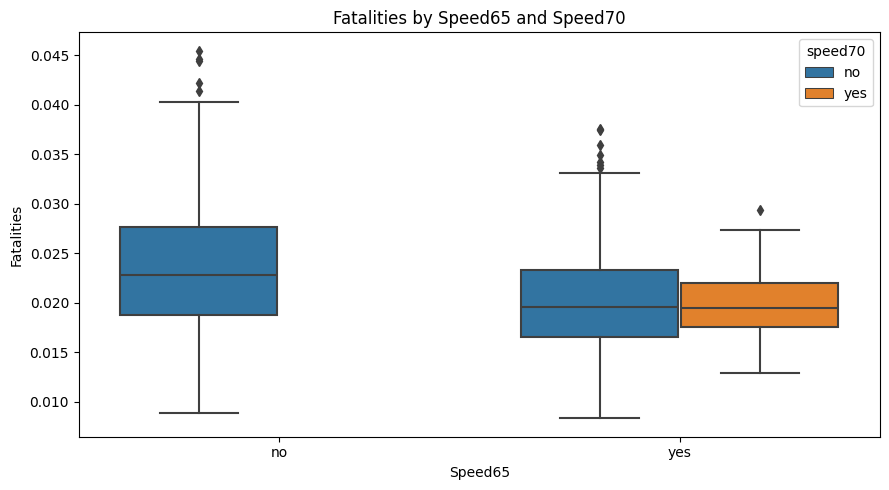

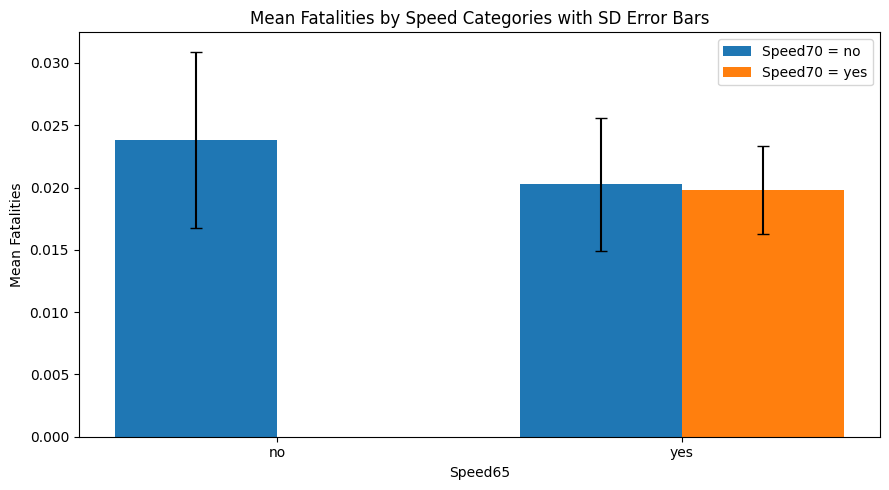

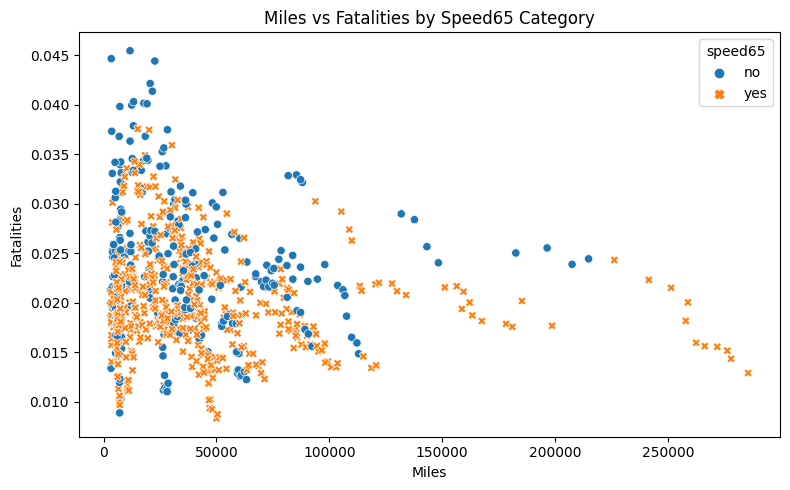


CORRELATIONS BY SPEED65 CATEGORY

Speed65 = no
Pearson correlation: -0.12218402764840869
Spearman correlation: -0.12094913565985152

Speed65 = yes
Pearson correlation: -0.1660640208506913
Spearman correlation: -0.15867439599552358

CORRELATION MATRIX
             miles  fatalities  income     age
miles       1.0000     -0.1614  0.2062  0.0835
fatalities -0.1614      1.0000 -0.7036 -0.3754
income      0.2062     -0.7036  1.0000  0.4075
age         0.0835     -0.3754  0.4075  1.0000


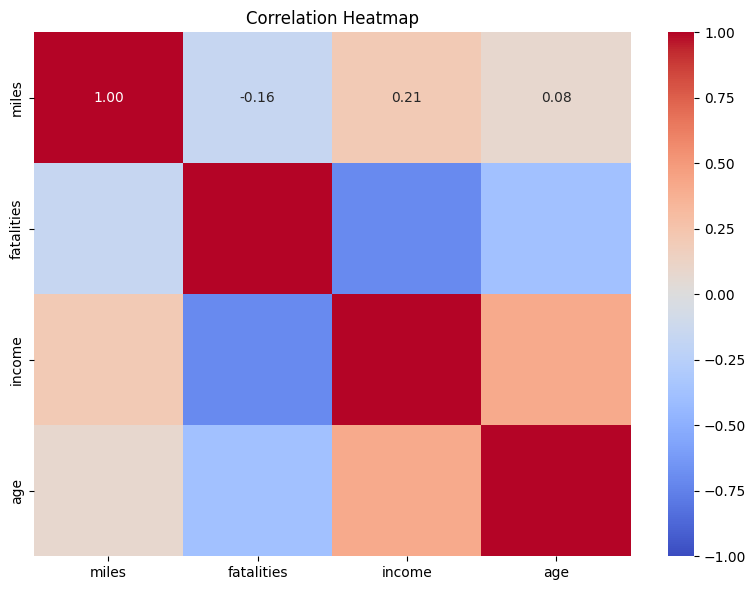

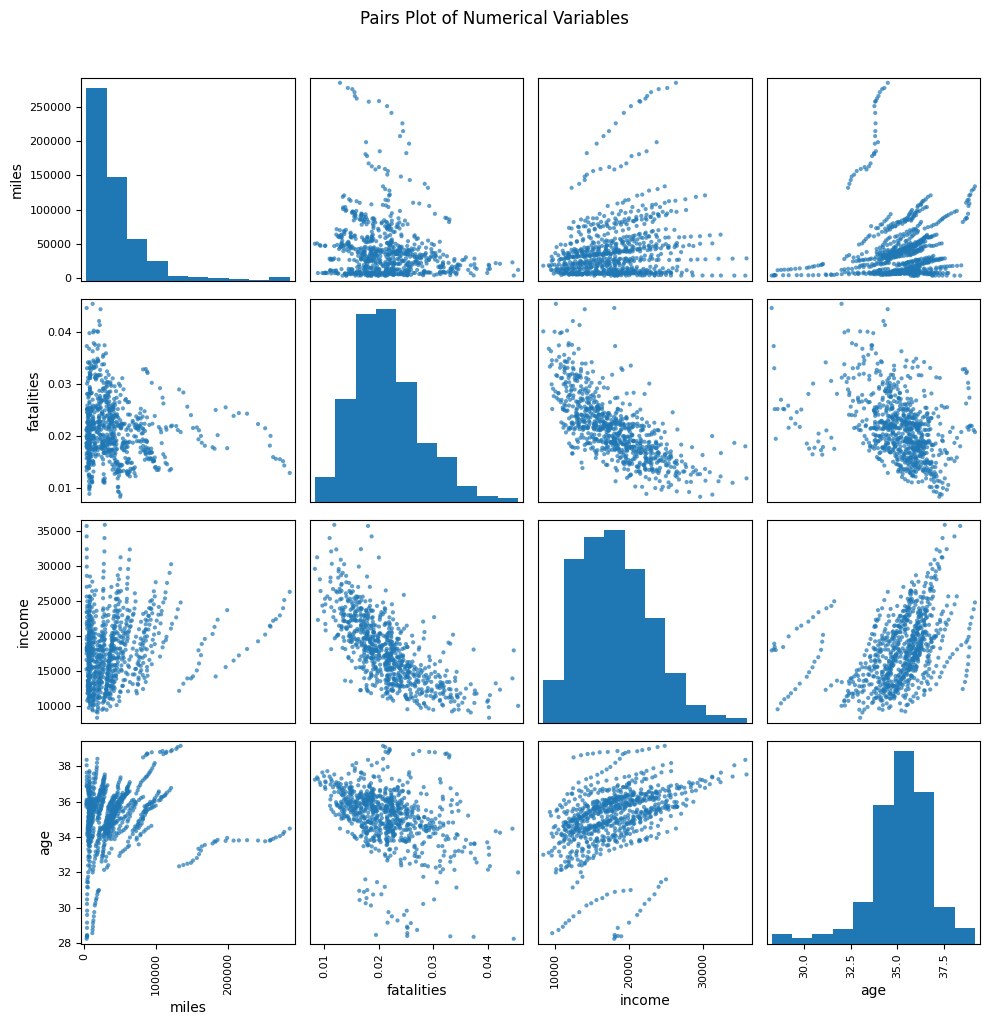

In [9]:
# Assignment 7

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, pearsonr, spearmanr
df = pd.read_csv("USSeatBelts.csv")

def show_data(df):
    print("\nDATASET INFORMATION")
    print("\nShape:", df.shape)
    print("\nColumns:", list(df.columns))
    print("\nData types:")
    df.info()

    print("\nFirst six rows:")
    print(df.head(6).to_string())

    print("\nLast six rows:")
    print(df.tail(6).to_string())

    print("\nSummary statistics:")
    print(df.describe(include="all").T.to_string())

show_data(df)
required_columns = [
    "fatalities", "seatbelt", "speed65", "speed70",
    "miles", "income", "age"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# 1-3. DESCRIPTIVE STATISTICS

x = pd.to_numeric(df["fatalities"], errors="coerce").dropna()

stats = {
    "Mean": x.mean(),
    "Median": x.median(),
    "Minimum": x.min(),
    "Maximum": x.max(),
    "Range": x.max() - x.min(),
    "Variance": x.var(),
    "Standard Deviation": x.std(),
    "IQR": x.quantile(0.75) - x.quantile(0.25),
    "Skewness": skew(x),
    "Kurtosis": kurtosis(x)
}

print("\nFATALITIES SUMMARY STATISTICS")
print(pd.Series(stats).to_string())

# 4. FREQUENCY AND RELATIVE FREQUENCY DISTRIBUTIONS

freq = df["seatbelt"].value_counts(dropna=False)
relative_freq = freq / freq.sum()

print("\nSEATBELT FREQUENCY DISTRIBUTION")
print(freq.to_string())

print("\nSEATBELT RELATIVE FREQUENCY DISTRIBUTION")
print(relative_freq.to_string())

print("\nSEATBELT PERCENTAGE DISTRIBUTION")
print((relative_freq * 100).round(2).to_string())

freq.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    title="Seatbelt Distribution"
)
plt.ylabel("")
plt.tight_layout()
plt.show()

freq.plot(
    kind="bar",
    figsize=(8, 5),
    title="Seatbelt Frequency Distribution"
)
plt.xlabel("Seatbelt")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 5. NUMERICAL FREQUENCY TABLE, HISTOGRAM AND BOX PLOT

bins = pd.cut(x, bins=10)

print("\nFATALITIES FREQUENCY DISTRIBUTION BY INTERVAL")
print(bins.value_counts().sort_index().to_string())

plt.figure(figsize=(8, 5))
plt.hist(x, bins=10, edgecolor="black")
plt.title("Histogram of Fatalities")
plt.xlabel("Fatalities")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
sns.boxplot(y=x)
plt.title("Box Plot of Fatalities")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()

# 6-7. CONTINGENCY TABLE, PROPORTIONS AND STACKED BAR PLOT

ct = pd.crosstab(df["speed65"], df["speed70"])

print("\nCONTINGENCY TABLE: SPEED65 VS SPEED70")
print(ct.to_string())

print("\nROW PROPORTIONS")
print(pd.crosstab(
    df["speed65"], df["speed70"], normalize="index"
).round(4).to_string())

print("\nCOLUMN PROPORTIONS")
print(pd.crosstab(
    df["speed65"], df["speed70"], normalize="columns"
).round(4).to_string())

ct.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    title="Stacked Bar Plot: Speed65 vs Speed70"
)
plt.xlabel("Speed65")
plt.ylabel("Frequency")
plt.legend(title="Speed70")
plt.tight_layout()
plt.show()

# 8. GROUPED MEAN, MEDIAN AND STANDARD DEVIATION

df["fatalities"] = pd.to_numeric(df["fatalities"], errors="coerce")

grouped_stats = df.groupby(
    "speed65", observed=False
)["fatalities"].agg(["mean", "median", "std"])

print("\nFATALITIES STATISTICS GROUPED BY SPEED65")
print(grouped_stats.to_string())

# 9. SIDE-BY-SIDE BOX PLOT AND VIOLIN PLOT

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="speed65", y="fatalities")
plt.title("Fatalities by Speed65")
plt.xlabel("Speed65")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="speed65", y="fatalities")
plt.title("Violin Plot of Fatalities by Speed65")
plt.xlabel("Speed65")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()

# 10. PEARSON AND SPEARMAN CORRELATIONS

paired = df[["miles", "fatalities"]].apply(
    pd.to_numeric, errors="coerce"
).dropna()

if len(paired) >= 2:
    print("\nPEARSON CORRELATION")
    print(pearsonr(paired["miles"], paired["fatalities"]))

    print("\nSPEARMAN CORRELATION")
    print(spearmanr(paired["miles"], paired["fatalities"]))

plt.figure(figsize=(8, 5))
sns.regplot(data=paired, x="miles", y="fatalities")
plt.title("Miles vs Fatalities with Linear Regression")
plt.xlabel("Miles")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()

# 11. TWO CATEGORICAL VARIABLES AND ONE NUMERICAL VARIABLE
grouped = df.groupby(
    ["speed65", "speed70"], observed=False
)["fatalities"].agg(["mean", "std", "count"]).reset_index()
print("\nMEAN AND STANDARD DEVIATION BY SPEED65 AND SPEED70")
print(grouped.to_string(index=False))
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="speed65",
    y="fatalities",
    hue="speed70"
)
plt.title("Fatalities by Speed65 and Speed70")
plt.xlabel("Speed65")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()
# Grouped mean bar chart with standard-deviation error bars
categories65 = list(df["speed65"].dropna().unique())
categories70 = list(df["speed70"].dropna().unique())
positions = np.arange(len(categories65))
width = 0.8 / max(len(categories70), 1)
fig, ax = plt.subplots(figsize=(9, 5))

for j, category70 in enumerate(categories70):
    subset = (
        grouped[grouped["speed70"] == category70]
        .set_index("speed65")
        .reindex(categories65)
    )

    offsets = positions - 0.4 + width / 2 + j * width

    ax.bar(
        offsets,
        subset["mean"],
        width=width,
        yerr=subset["std"],
        capsize=4,
        label=f"Speed70 = {category70}"
    )
ax.set_xticks(positions)
ax.set_xticklabels([str(category) for category in categories65])
ax.set_xlabel("Speed65")
ax.set_ylabel("Mean Fatalities")
ax.set_title("Mean Fatalities by Speed Categories with SD Error Bars")
ax.legend()
plt.tight_layout()
plt.show()

# 12. CATEGORY-COLORED SCATTER PLOT AND CATEGORY-WISE CORRELATIONS

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="miles",
    y="fatalities",
    hue="speed65",
    style="speed65"
)
plt.title("Miles vs Fatalities by Speed65 Category")
plt.xlabel("Miles")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()

print("\nCORRELATIONS BY SPEED65 CATEGORY")

for category, group in df.groupby("speed65", observed=False):
    subset = group[["miles", "fatalities"]].apply(
        pd.to_numeric, errors="coerce"
    ).dropna()

    print(f"\nSpeed65 = {category}")

    if len(subset) >= 2 and subset["miles"].nunique() > 1 and subset["fatalities"].nunique() > 1:
        print(
            "Pearson correlation:",
            subset["miles"].corr(
                subset["fatalities"], method="pearson"
            )
        )
        print(
            "Spearman correlation:",
            subset["miles"].corr(
                subset["fatalities"], method="spearman"
            )
        )
    else:
        print("Insufficient variation or observations for correlation.")

# 13. CORRELATION MATRIX AND HEATMAP

num = df[["miles", "fatalities", "income", "age"]].apply(
    pd.to_numeric, errors="coerce"
)

corr_matrix = num.corr()

print("\nCORRELATION MATRIX")
print(corr_matrix.round(4).to_string())

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 14. PAIRS PLOT / SCATTERPLOT MATRIX

pairs_data = num.dropna()

pd.plotting.scatter_matrix(
    pairs_data,
    figsize=(10, 10),
    diagonal="hist",
    alpha=0.7
)

plt.suptitle("Pairs Plot of Numerical Variables", y=1.02)
plt.tight_layout()
plt.show()


SHAPE: (765, 13)

COLUMNS: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

DATA INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    object 
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    object 
 7   speed70     765 non-null    object 
 8   drinkage    765 non-null    object 
 9   alcohol     765 non-null    object 
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 77.8+ KB

FIRST SIX ROWS:
    rownames st

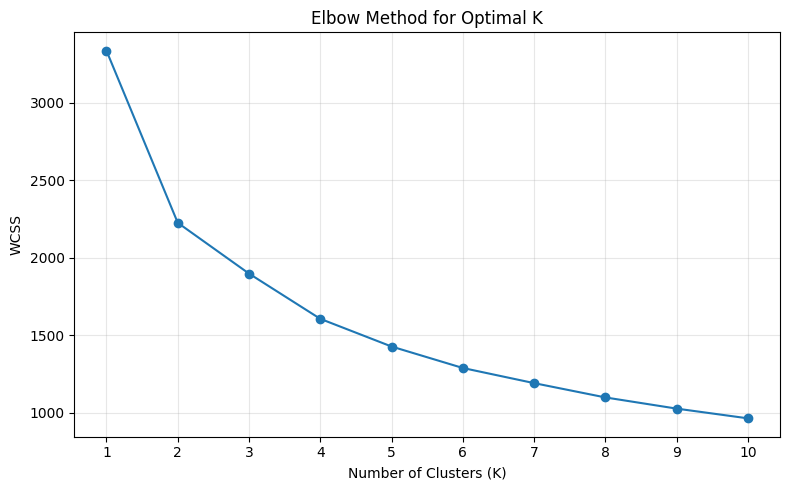


SELECTED K FOR FINAL K-MEANS MODEL: 3

FINAL K-MEANS CLUSTER CENTERS:
     year     miles  fatalities  seatbelt    income       age
 0.059840  3.814949   -0.201043  0.776716  0.298945 -1.147176
 0.659596 -0.069147   -0.535606  0.538862  0.645829  0.402399
-0.822163 -0.249566    0.681009 -0.735624 -0.826122 -0.397570

FINAL K-MEANS CLUSTER COUNTS:
0     21
1    296
2    239

FINAL K-MEANS ASSIGNMENTS (K = 3)
---------------------------------------------
Total observations: 556
Number of clusters: 3

CLUSTER COUNTS:
Cluster
0     21
1    296
2    239

FIRST 20 CLUSTER ASSIGNMENTS:
 Observation  Cluster
           7        2
           8        2
           9        2
          10        2
          11        1
          12        1
          13        1
          14        1
          16        2
          17        2
          18        2
          19        2
          20        2
          21        2
          22        2
          23        2
          24        2
          25     

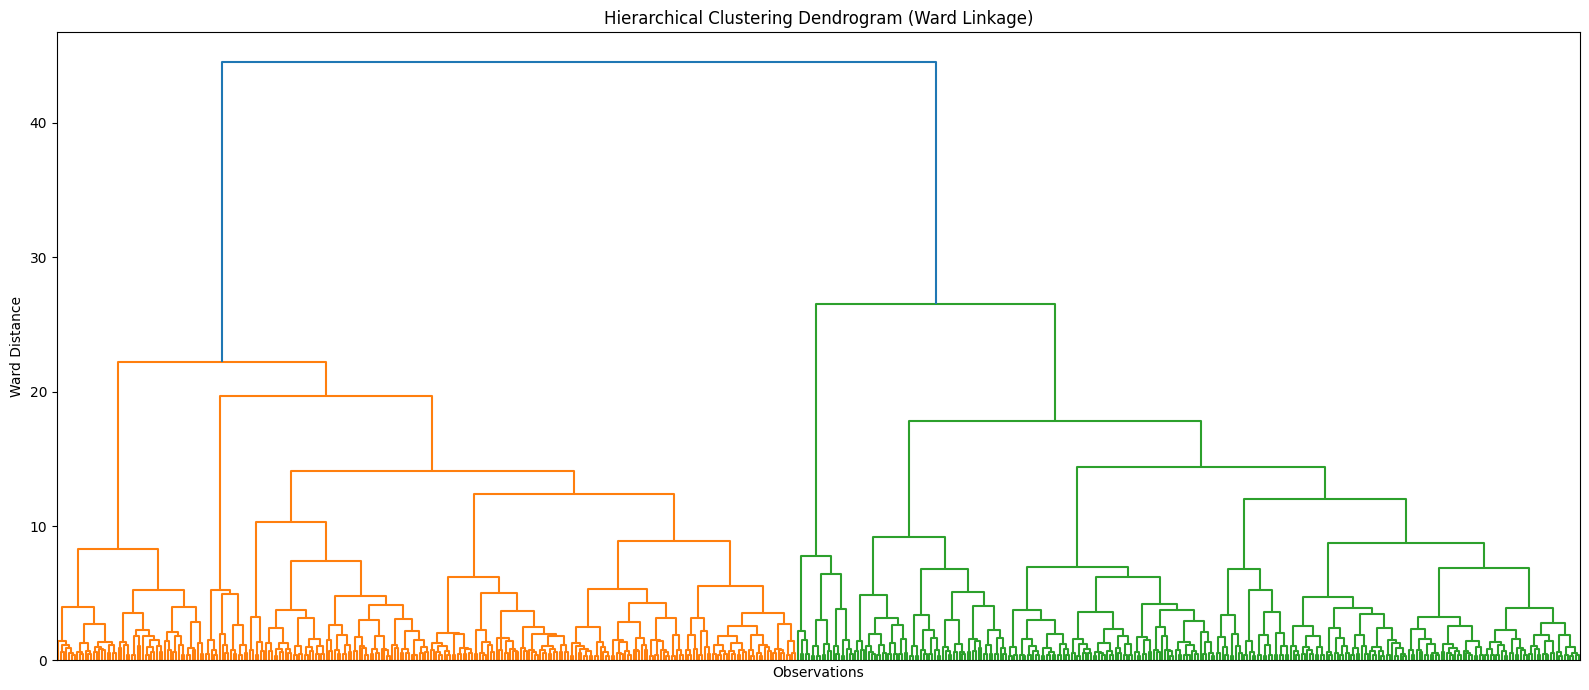


HIERARCHICAL CLUSTER ASSIGNMENTS (3 CLUSTERS)
---------------------------------------------
Total observations: 556
Number of clusters: 3

CLUSTER COUNTS:
Cluster
1    270
2     21
3    265

FIRST 20 CLUSTER ASSIGNMENTS:
 Observation  Cluster
           7        1
           8        1
           9        1
          10        1
          11        1
          12        1
          13        1
          14        1
          16        1
          17        1
          18        1
          19        1
          20        1
          21        1
          22        1
          23        1
          24        3
          25        3
          26        3
          27        3

LAST 10 CLUSTER ASSIGNMENTS:
 Observation  Cluster
         748        3
         749        3
         757        1
         758        1
         759        1
         760        1
         761        3
         762        3
         763        3
         764        3

Complete assignments saved to:
hierarchical

In [10]:
# Assignment 8

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
df = pd.read_csv("USSeatBelts.csv")


def show_data(df):
    print("\nSHAPE:", df.shape)
    print("\nCOLUMNS:", list(df.columns))

    print("\nDATA INFORMATION:")
    df.info()

    print("\nFIRST SIX ROWS:\n", df.head(6))
    print("\nLAST SIX ROWS:\n", df.tail(6))
    print("\nSUMMARY STATISTICS:\n", df.describe(include="all").T)
def display_assignments(results, title, output_path):
    print(f"\n{title}")
    print("-" * 45)
    print("Total observations:", len(results))
    print("Number of clusters:", results["Cluster"].nunique())

    print("\nCLUSTER COUNTS:")
    print(results["Cluster"].value_counts().sort_index().to_string())

    print("\nFIRST 20 CLUSTER ASSIGNMENTS:")
    print(results.head(20).to_string(index=False))

    print("\nLAST 10 CLUSTER ASSIGNMENTS:")
    print(results.tail(10).to_string(index=False))

    results.to_csv(output_path, index=False)
    print("\nComplete assignments saved to:")
    print(output_path)


show_data(df)
# Check missing values
print("\nMISSING VALUES IN EACH COLUMN:")
print(df.isnull().sum().to_string())
print("\nTOTAL MISSING VALUES:", df.isnull().sum().sum())
# Display distributions of relevant categorical variables
for col in ["state", "speed65", "speed70", "drinkage", "alcohol", "enforce"]:
    if col in df.columns:
        print(f"\nDISTRIBUTION OF {col.upper()}:")
        print(df[col].value_counts(dropna=False).to_string())
# Select numerical features
num = df.select_dtypes(include=np.number).drop(
    columns=["rownames"], errors="ignore"
)
print("\nNUMERICAL FEATURES:")
print(list(num.columns))
# Remove rows with missing numerical values
rows_before = len(num)
num = num.dropna()
rows_dropped = rows_before - len(num)
print("\nROWS BEFORE REMOVING MISSING VALUES:", rows_before)
print("ROWS DROPPED:", rows_dropped)
print("ROWS USED FOR CLUSTERING:", len(num))
if len(num) < 3:
    raise ValueError("At least 3 complete observations are required.")
# Standardize numerical features
scaler = StandardScaler()

scaled = scaler.fit_transform(num)
scaled_df = pd.DataFrame(scaled, columns=num.columns, index=num.index)
print("\nSTANDARDIZED DATA (FIRST SIX ROWS):")
print(scaled_df.head(6).to_string())

# Apply K-Means with K = 2
km2 = KMeans(n_clusters=2, n_init=25, random_state=123)
km2_labels = km2.fit_predict(scaled)
print("\nK-MEANS CLUSTERING (K = 2)")
print("-" * 45)
print("\nCLUSTER CENTERS (STANDARDIZED FEATURES):")
print(pd.DataFrame(
    km2.cluster_centers_, columns=num.columns
).to_string(index=False))
print("\nCLUSTER CENTERS (ORIGINAL UNITS):")
print(pd.DataFrame(
    scaler.inverse_transform(km2.cluster_centers_),
    columns=num.columns
).to_string(index=False))
print("\nCLUSTER COUNTS:")
print(pd.Series(km2_labels).value_counts().sort_index().to_string())
km2_results = pd.DataFrame({
    "Observation": num.index,
    "Cluster": km2_labels
})
display_assignments(
    km2_results,
    "K-MEANS ASSIGNMENTS (K = 2)",
    "kmeans_k2_assignments.csv"
)

# Calculate WCSS for K = 1 to 10
max_k = min(10, len(scaled))
ks = range(1, max_k + 1)
wcss = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=25, random_state=123)
    model.fit(scaled)
    wcss.append(model.inertia_)
# Print numerical WCSS scores
print("\nWCSS SCORES:")
print("-" * 45)
print(f"{'K':<10}{'WCSS':>15}")
print("-" * 25)
for k, score in zip(ks, wcss):
    print(f"{k:<10}{score:>15.4f}")
# Plot elbow curve
plt.figure(figsize=(8, 5))
plt.plot(list(ks), wcss, marker="o")
plt.xticks(list(ks))
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# Select K after examining the elbow plot
# Change this value if the elbow suggests another K
optimal_k = min(3, len(scaled))

print(f"\nSELECTED K FOR FINAL K-MEANS MODEL: {optimal_k}")
final_kmeans = KMeans(
    n_clusters=optimal_k,
    n_init=25,
    random_state=123
)
final_labels = final_kmeans.fit_predict(scaled)
print("\nFINAL K-MEANS CLUSTER CENTERS:")
print(pd.DataFrame(
    final_kmeans.cluster_centers_,
    columns=num.columns
).to_string(index=False))
print("\nFINAL K-MEANS CLUSTER COUNTS:")
print(pd.Series(final_labels).value_counts().sort_index().to_string())
final_results = pd.DataFrame({
    "Observation": num.index,
    "Cluster": final_labels
})
display_assignments(
    final_results,
    f"FINAL K-MEANS ASSIGNMENTS (K = {optimal_k})",
    "kmeans_final_assignments.csv"
)

# Calculate Euclidean distances
euclidean_distances = pdist(scaled, metric="euclidean")

print("\nHIERARCHICAL CLUSTERING")
print("-" * 45)
print("Distance metric: Euclidean")
print("Linkage method: Ward")
print("Number of pairwise distances:", len(euclidean_distances))
print("First 10 Euclidean distances:", np.round(euclidean_distances[:10], 4))

# Perform Ward hierarchical clustering using all observations
Z = linkage(scaled, method="ward", metric="euclidean")

# Plot dendrogram
plt.figure(figsize=(16, 7))
dendrogram(Z, no_labels=True)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Observations")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

# Divide observations into 3 hierarchical clusters
hc_labels = fcluster(Z, t=3, criterion="maxclust")

hc_results = pd.DataFrame({
    "Observation": num.index,
    "Cluster": hc_labels
})

display_assignments(
    hc_results,
    "HIERARCHICAL CLUSTER ASSIGNMENTS (3 CLUSTERS)",
    "hierarchical_cluster_assignments.csv"
)

# Cross-check using sklearn AgglomerativeClustering
hc_model = AgglomerativeClustering(n_clusters=3, linkage="ward")
hc_sklearn_labels = hc_model.fit_predict(scaled) + 1

print("\nAGGLOMERATIVE CLUSTERING COUNTS (SKLEARN):")
print(pd.Series(hc_sklearn_labels).value_counts().sort_index().to_string())

FIRST SIX ROWS


,rownames,state,year,miles,fatalities,seatbelt,speed65,speed70,drinkage,alcohol,income,age,enforce
0,1,AK,1983,3358,0.044669,NaN,no,no,yes,no,17973,28.234966,no
1,2,AK,1984,3589,0.037336,NaN,no,no,yes,no,18093,28.343542,no
2,3,AK,1985,3840,0.033073,NaN,no,no,yes,no,18925,28.372816,no
3,4,AK,1986,4008,0.025200,NaN,no,no,yes,no,18466,28.396652,no
4,5,AK,1987,3900,0.019487,NaN,no,no,yes,no,18021,28.453251,no
5,6,AK,1988,3841,0.025254,NaN,no,no,yes,no,18447,28.851419,no



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    object 
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    object 
 7   speed70     765 non-null    object 
 8   drinkage    765 non-null    object 
 9   alcohol     765 non-null    object 
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 77.8+ KB

NUMBER OF ROWS: 765
NUMBER OF COLUMNS: 13

NUMERIC DATA AFTER CLEANING


,rownames,year,miles,fatalities,seatbelt,income,age
0,1,1983,3358,0.044669,0.55,17973,28.234966
1,2,1984,3589,0.037336,0.55,18093,28.343542
2,3,1985,3840,0.033073,0.55,18925,28.372816
3,4,1986,4008,0.025200,0.55,18466,28.396652
4,5,1987,3900,0.019487,0.55,18021,28.453251


Dimensions after cleaning: (765, 7)

SUMMARY OF NORMALIZED DATA


,rownames,year,miles,fatalities,seatbelt,income,age
count,7.650000e+02,7.650000e+02,7.650000e+02,7.650000e+02,7.650000e+02,7.650000e+02,7.650000e+02
mean,-7.430512e-17,2.902544e-18,2.786442e-17,-9.752547e-17,1.671865e-16,1.857628e-16,-8.545089e-16
std,1.000654e+00,1.000654e+00,1.000654e+00,1.000654e+00,1.000654e+00,1.000654e+00,1.000654e+00
min,-1.729788e+00,-1.620185e+00,-8.728864e-01,-2.134204e+00,-3.267379e+00,-2.000824e+00,-4.067261e+00
25%,-8.648941e-01,-9.258201e-01,-6.839179e-01,-6.726609e-01,-3.691893e-01,-7.750299e-01,-4.417699e-01
50%,0.000000e+00,0.000000e+00,-2.533101e-01,-4.711276e-02,1.058113e-01,-7.665618e-02,1.500111e-01
75%,8.648941e-01,9.258201e-01,2.472903e-01,5.325825e-01,5.876956e-01,6.420990e-01,5.854926e-01
max,1.729788e+00,1.620185e+00,5.557619e+00,3.888372e+00,2.308711e+00,3.716566e+00,2.376157e+00



PCA SUMMARY


,Principal Component,Standard Deviation,Proportion of Variance,Percentage of Variance,Cumulative Percentage
0,PC1,1.7119,0.4181,41.8109,41.8109
1,PC2,1.0337,0.1525,15.2452,57.0561
2,PC3,0.9864,0.1388,13.8802,70.9363
3,PC4,0.9332,0.1242,12.4237,83.3600
4,PC5,0.7879,0.0886,8.8557,92.2157
5,PC6,0.6218,0.0552,5.5170,97.7328
6,PC7,0.3986,0.0227,2.2672,100.0000


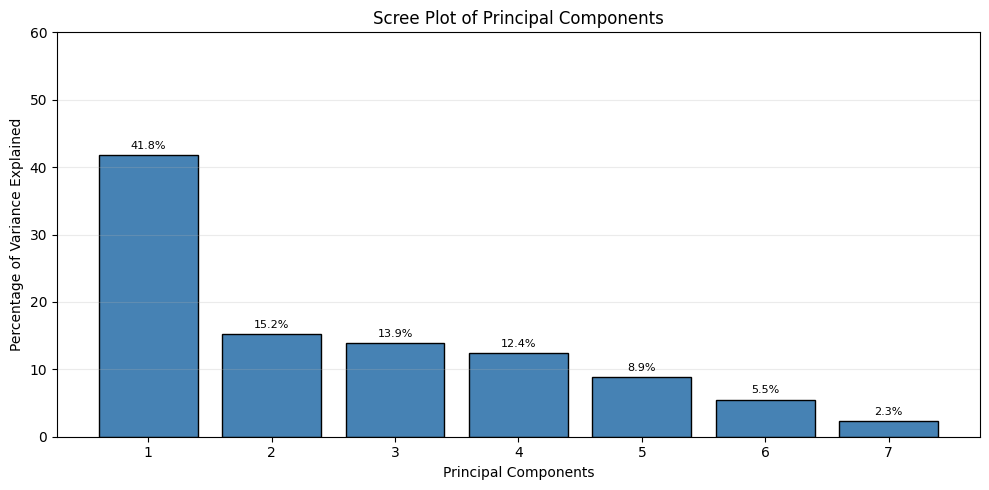

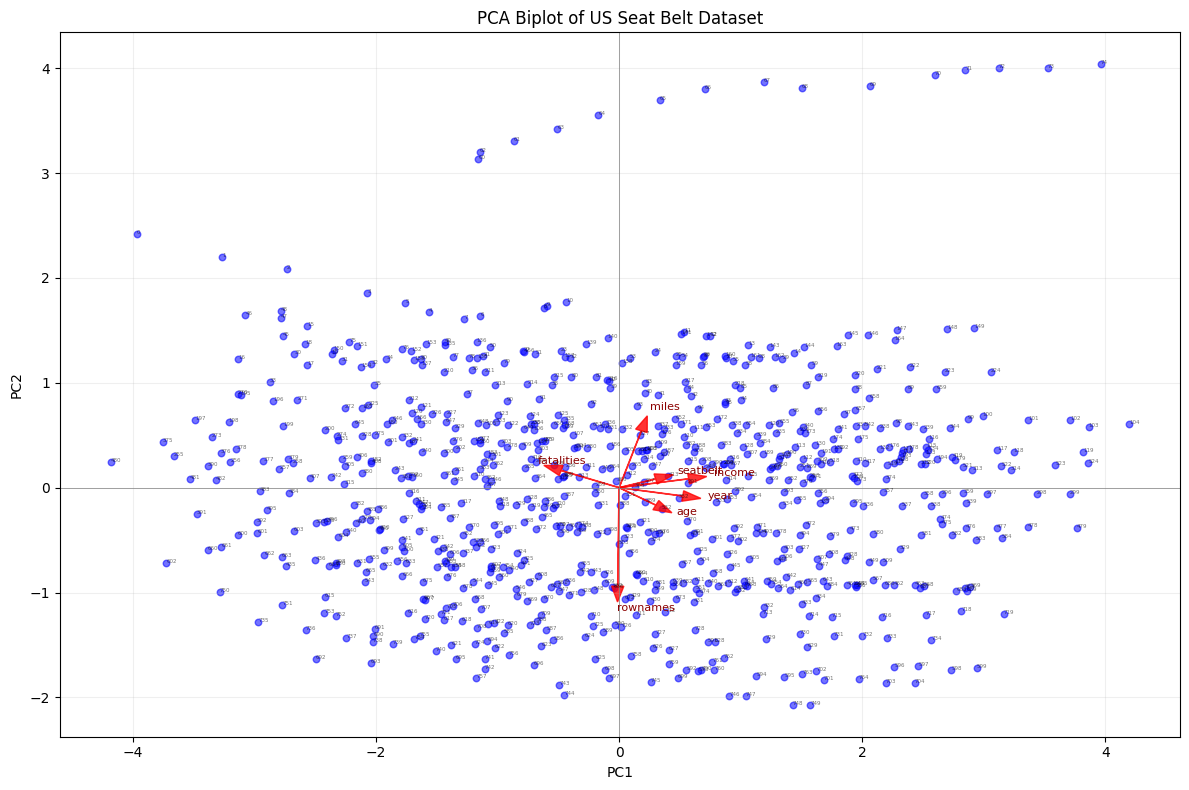


FIRST SIX ROWS OF PCA SCORES


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,-3.967575,2.419554,1.162309,3.031346,-0.516311,1.140065,1.829507
1,-3.266818,2.202898,0.999912,2.890917,-1.113415,0.593799,1.346675
2,-2.731552,2.085517,0.902000,2.853916,-1.509938,0.361875,1.147960
3,-2.071495,1.853592,0.763466,2.710031,-2.163670,-0.244566,0.541160
4,-1.566663,1.670800,0.651435,2.608461,-2.622636,-0.645337,0.052477
5,-1.759380,1.762152,0.635499,2.685440,-2.012880,0.058695,0.320193


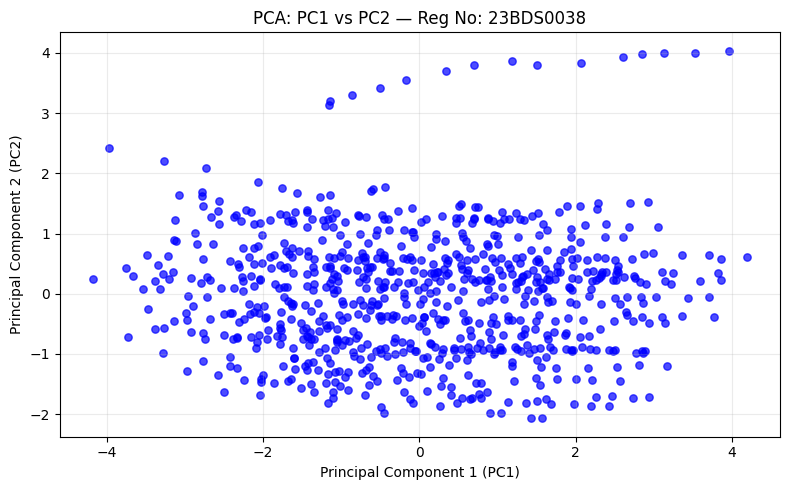

In [11]:
# Assignment 9 

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Load the USSeatBelts dataset.
data = pd.read_csv("USSeatBelts.csv")

print("FIRST SIX ROWS")
display(data.head(6))
print("\nDATASET INFORMATION")
data.info()

# 2. Display the total number of rows and columns.
print("\nNUMBER OF ROWS:", data.shape[0])
print("NUMBER OF COLUMNS:", data.shape[1])

# 3. Extract numeric columns and clean the data.
numeric_data = data.select_dtypes(include=np.number).copy()
numeric_data = numeric_data.dropna(axis=1, how="all")

# Replace missing numeric values with the median of each column.
for column in numeric_data.columns:
    numeric_data[column] = numeric_data[column].fillna(
        numeric_data[column].median()
    )

# Remove columns with zero standard deviation.
numeric_data = numeric_data.loc[:, numeric_data.std() > 0]

print("\nNUMERIC DATA AFTER CLEANING")
display(numeric_data.head())
print("Dimensions after cleaning:", numeric_data.shape)

# Normalize the data using standard scaling (equivalent to scale()).
scaler = StandardScaler()
data_scaled_array = scaler.fit_transform(numeric_data)
data_scaled = pd.DataFrame(
    data_scaled_array,
    columns=numeric_data.columns,
    index=numeric_data.index
)

print("\nSUMMARY OF NORMALIZED DATA")
display(data_scaled.describe())

# 4. Perform PCA and display its summary.
pca_result = PCA()
pca_array = pca_result.fit_transform(data_scaled)

variance_percent = pca_result.explained_variance_ratio_ * 100
cumulative_percent = np.cumsum(variance_percent)

pca_summary = pd.DataFrame({
    "Principal Component": [
        f"PC{i + 1}" for i in range(len(variance_percent))
    ],
    "Standard Deviation": np.sqrt(pca_result.explained_variance_),
    "Proportion of Variance": pca_result.explained_variance_ratio_,
    "Percentage of Variance": variance_percent,
    "Cumulative Percentage": cumulative_percent
})

print("\nPCA SUMMARY")
display(pca_summary.round(4))

# 5. Scree plot showing percentage of variance, with data labels.
plt.figure(figsize=(10, 5))
bars = plt.bar(
    range(1, len(variance_percent) + 1),
    variance_percent,
    color="steelblue",
    edgecolor="black"
)
for bar, value in zip(bars, variance_percent):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.6,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.ylim(0, 60)
plt.xlabel("Principal Components")
plt.ylabel("Percentage of Variance Explained")
plt.title("Scree Plot of Principal Components")
plt.xticks(range(1, len(variance_percent) + 1))
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 6. PCA biplot with observation and variable labels.
pca_scores = pd.DataFrame(
    pca_array,
    columns=[f"PC{i + 1}" for i in range(pca_array.shape[1])],
    index=data.index
)

loadings = pca_result.components_.T
fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    color="blue",
    alpha=0.55,
    s=22,
    label="Observations"
)

# Add observation labels. adjustText is used when available to reduce overlap.
try:
    from adjustText import adjust_text
    texts = [
        ax.text(x, y, str(label), fontsize=5, alpha=0.75)
        for label, x, y in zip(
            data.index, pca_scores["PC1"], pca_scores["PC2"]
        )
    ]
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.3))
except ImportError:
    # Fallback: show labels with a small font if adjustText is unavailable.
    for label, x, y in zip(data.index, pca_scores["PC1"], pca_scores["PC2"]):
        ax.annotate(str(label), (x, y), fontsize=4, alpha=0.55)

# Scale loading arrows so they are visible alongside the PCA scores.
score_range = max(
    np.ptp(pca_scores["PC1"]),
    np.ptp(pca_scores["PC2"]),
    1
)
arrow_scale = score_range * 0.16

for i, variable in enumerate(numeric_data.columns):
    dx = loadings[i, 0] * arrow_scale
    dy = loadings[i, 1] * arrow_scale
    ax.arrow(
        0, 0, dx, dy,
        color="red",
        width=0.003,
        head_width=score_range * 0.012,
        length_includes_head=True,
        alpha=0.8
    )
    ax.text(
        dx * 1.08, dy * 1.08, variable,
        color="darkred", fontsize=8
    )

ax.set_title("PCA Biplot of US Seat Belt Dataset")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 7. Extract PCA scores into pca_scores and display the first six rows.
print("\nFIRST SIX ROWS OF PCA SCORES")
display(pca_scores.head(6))

# 8. Scatter plot of PC1 vs PC2 with registration number in the title.
plt.figure(figsize=(8, 5))
plt.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    color="blue",
    marker="o",
    s=28,
    alpha=0.7
)
plt.title("PCA: PC1 vs PC2 — Reg No: 23BDS0038")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Duplicate records: 0

DESCRIPTIVE STATISTICS
               miles  fatalities
count     765.000000  765.000000
mean    41447.734641    0.021490
std     43961.990037    0.006171
min      3099.000000    0.008327
25%     11401.000000    0.017341
50%     30319.000000    0.021199
75%     52312.000000    0.024774
max    285612.000000    0.045470

Mean:
 miles         41447.734641
fatalities        0.021490
dtype: float64

Median:
 miles         30319.000000
fatalities        0.021199
dtype: float64

Variance:
 miles         1.932657e+09
fatalities    3.808488e-05
dtype: float64

Standard Deviation:
 miles         43961.990037
fatalities        0.006171
dtype: float64


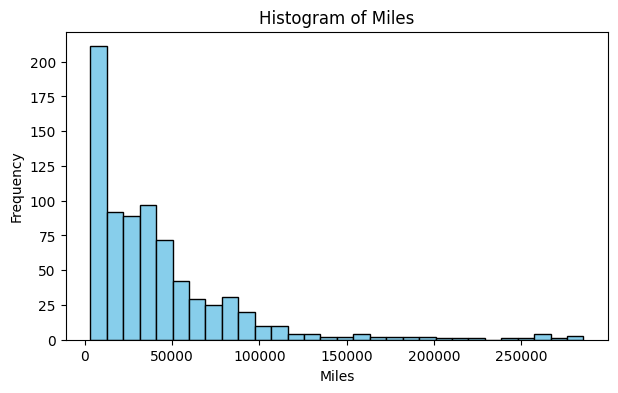

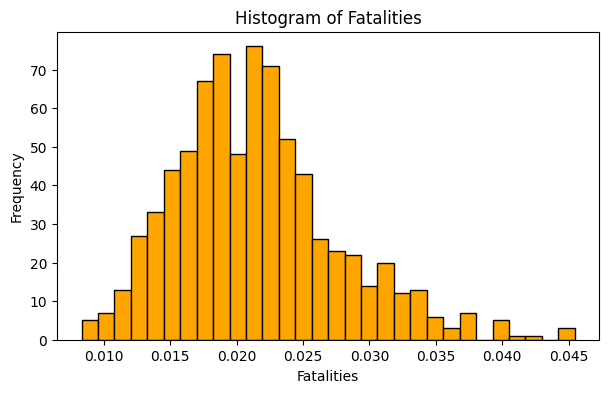

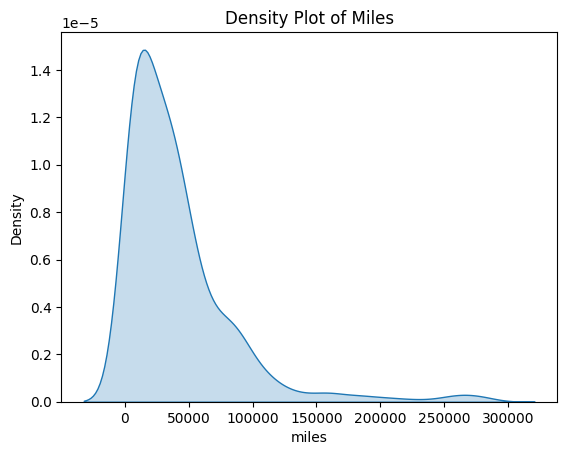

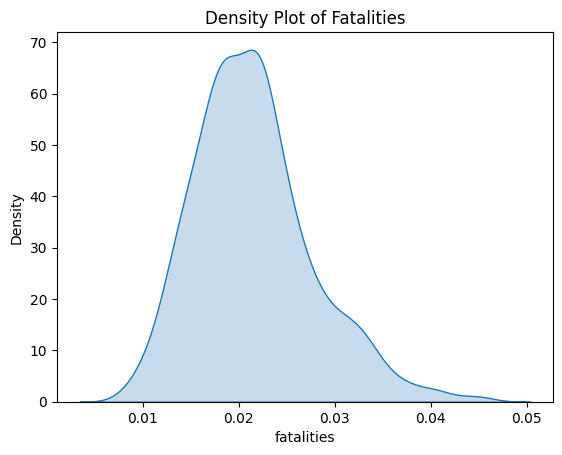

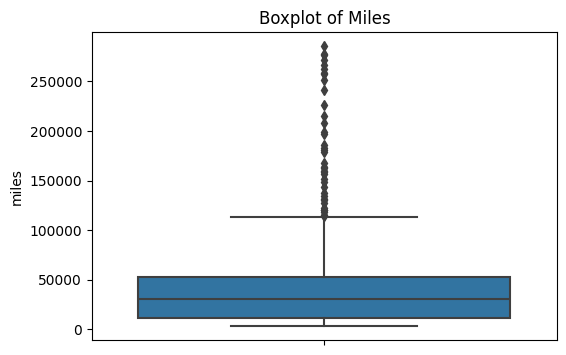

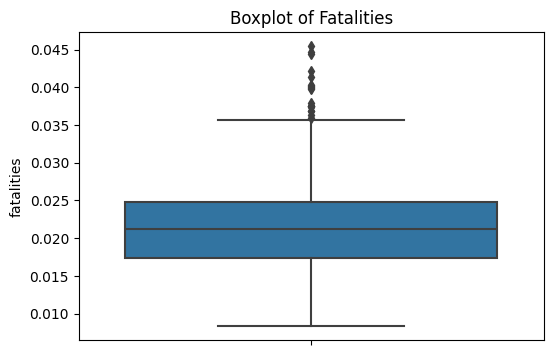


Outliers in miles: 39
Lower limit: -49965.5
Upper limit: 113678.5

Outliers in fatalities: 19
Lower limit: 0.0061914660036562486
Upper limit: 0.03592366352677345


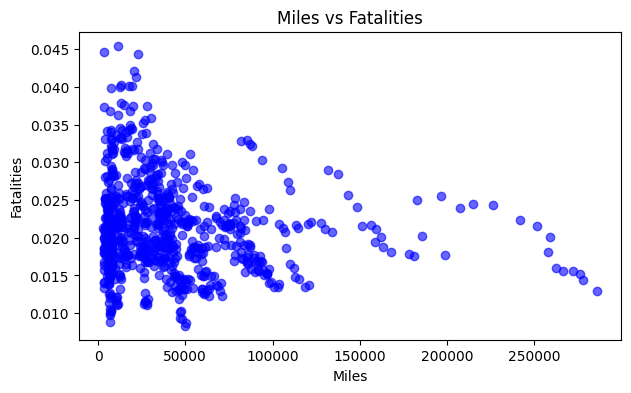


Pearson Correlation: -0.1613660714756055


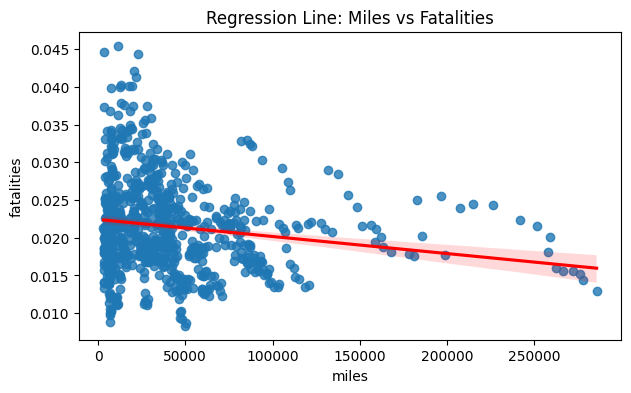


INTERCEPT: 0.022293870803843673
SLOPE: -2.0869867477312444e-08

Regression Equation: Y = 0.022294 + -0.0000000209 * X

R-SQUARED: 0.04164341952295325

RESIDUALS:
178   -0.003695
332    0.002035
618   -0.000682
172   -0.000182
713   -0.006642
Name: fatalities, dtype: float64

MODEL EVALUATION
MAE: 0.004292120579547089
MSE: 3.364261480216289e-05
RMSE: 0.005800225409599431
MAPE: 20.95901456385222


In [14]:
# Assignment 10

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("USSeatBelts.csv")

# Handle missing values
for col in df.columns:
    if df[col].isna().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

# Remove duplicate records
print("Duplicate records:", df.duplicated().sum())
df = df.drop_duplicates()

# Select independent and dependent variables
X = df[["miles"]]
Y = df["fatalities"]

# Descriptive statistics
print("\nDESCRIPTIVE STATISTICS")
print(df[["miles", "fatalities"]].describe())

print("\nMean:\n", df[["miles", "fatalities"]].mean())
print("\nMedian:\n", df[["miles", "fatalities"]].median())
print("\nVariance:\n", df[["miles", "fatalities"]].var())
print("\nStandard Deviation:\n", df[["miles", "fatalities"]].std())

# Histograms
plt.figure(figsize=(7, 4))
plt.hist(X["miles"], bins=30, color="skyblue", edgecolor="black")
plt.title("Histogram of Miles")
plt.xlabel("Miles")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(Y, bins=30, color="orange", edgecolor="black")
plt.title("Histogram of Fatalities")
plt.xlabel("Fatalities")
plt.ylabel("Frequency")
plt.show()

# Density plots
sns.kdeplot(x=df["miles"], fill=True)
plt.title("Density Plot of Miles")
plt.show()

sns.kdeplot(x=df["fatalities"], fill=True)
plt.title("Density Plot of Fatalities")
plt.show()

# Boxplots
plt.figure(figsize=(6, 4))
sns.boxplot(y=df["miles"])
plt.title("Boxplot of Miles")
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(y=df["fatalities"])
plt.title("Boxplot of Fatalities")
plt.show()

# Outlier detection using IQR
for col in ["miles", "fatalities"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\nOutliers in {col}: {len(outliers)}")
    print("Lower limit:", lower)
    print("Upper limit:", upper)

# Scatter plot
plt.figure(figsize=(7, 4))
plt.scatter(X, Y, color="blue", alpha=0.6)
plt.title("Miles vs Fatalities")
plt.xlabel("Miles")
plt.ylabel("Fatalities")
plt.show()

# Correlation
correlation = df["miles"].corr(df["fatalities"])
print("\nPearson Correlation:", correlation)

# Regression line
plt.figure(figsize=(7, 4))
sns.regplot(
    data=df,
    x="miles",
    y="fatalities",
    line_kws={"color": "red"}
)
plt.title("Regression Line: Miles vs Fatalities")
plt.show()

# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=123
)

# Simple Linear Regression
model = LinearRegression()
model.fit(X_train, Y_train)

# Model predictions
Y_pred = model.predict(X_test)

# Intercept and slope
print("\nINTERCEPT:", model.intercept_)
print("SLOPE:", model.coef_[0])

# Regression equation
print(
    f"\nRegression Equation: Y = "
    f"{model.intercept_:.6f} + "
    f"{model.coef_[0]:.10f} * X"
)

# R-squared
print("\nR-SQUARED:", r2_score(Y_test, Y_pred))

# Residuals
residuals = Y_test - Y_pred

print("\nRESIDUALS:")
print(residuals.head())

# Evaluation metrics
MAE = mean_absolute_error(Y_test, Y_pred)
MSE = mean_squared_error(Y_test, Y_pred)
RMSE = np.sqrt(MSE)

nonzero = Y_test != 0
MAPE = np.mean(
    np.abs(residuals[nonzero] / Y_test[nonzero])
) * 100

print("\nMODEL EVALUATION")
print("MAE:", MAE)
print("MSE:", MSE)
print("RMSE:", RMSE)
print("MAPE:", MAPE)